# 02 · Modelos: ¿cuántos viajeros esperar y quién se aloja en hotel?

**Para:** Gerencia Comercial y Técnica · **Metodología:** CRISP-DM — este notebook cubre las fases **3. Preparación de datos**, **4. Modelado** y **5. Evaluación** (las fases 1 y 2, negocio y datos, están en `01_eda.ipynb`; la conclusión, en `03_conclusiones.ipynb`).

**Lo que responde este notebook, en una línea cada uno:**

1. **Pronóstico de demanda.** Con el contexto económico de los hogares, el modelo elegido (**Random Forest**) se equivoca en promedio **±6,0 %** de los viajeros de cada mes, contra **±6,3 %** de lo que se haría “a ojo” (repetir el mismo mes del año anterior). La ventaja aparece justo en los años de crisis, que es cuando más plata hay en juego.
2. **¿Qué turista se aloja en hotel?** Un clasificador sobre la encuesta de hogares (EVyTH) separa bien a quienes van a hotel (AUC 0,78) y deja reglas simples para dirigir promociones: **viaje de ocio fuera de la provincia de Buenos Aires, sin auto propio y de hogares de ingresos altos → 2 de cada 3 van a hotel**, casi el triple del promedio (24 %).
3. **Demanda por región.** El modelo de Tina, corregido (Random Forest sobre la variación interanual, con vuelos de cabotaje rezagados 12 meses), con salario real, inflación y actividad (y restricciones de monotonía para que respeten su signo esperado) se equivoca **9,01 %** contra **9,12 %** de la regla simple: le gana por poco (sobre todo en CABA y Litoral). Como usa la macro, **los escenarios económicos también mueven la proyección por región**, en el orden esperado.
4. **Horizonte.** El último dato real es noviembre 2025; la ventana de pronóstico es noviembre 2026 – octubre 2027 y los 11 meses del medio son **puente**. A 2 años de distancia el error del modelo nacional sube de 5,7 % a 8,9 %.

| Pregunta de negocio | Tipo de aprendizaje | Variable objetivo (*target*) | Datos |
|---|---|---|---|
| ¿Cuántos viajeros residentes se van a alojar el mes *m*? | Supervisado · **regresión** | Variación interanual de viajeros (%) | EOH (INDEC) + macro (INDEC, BCRA) · mensual |
| ¿Este viaje se aloja en hotel? | Supervisado · **clasificación** | Hotel sí/no | EVyTH (microdatos) · por viaje |

> **Cómo leer los errores.** **MAPE** (error porcentual absoluto medio) = “en promedio, nos equivocamos en ±X % de los viajeros del mes”. **MAE** (error absoluto medio) = lo mismo en unidades (viajeros o puntos porcentuales). **AUC** = probabilidad de que el modelo le ponga más puntaje a un viaje que sí fue a hotel que a uno que no (0,5 = azar, 1 = perfecto).

In [1]:
import sys
import warnings
from pathlib import Path

RAIZ = Path.cwd().resolve().parent
sys.path.insert(0, str(RAIZ / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

IMG = RAIZ / "docs" / "img"
IMG.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "font.size": 14, "axes.titlesize": 17, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 14, "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 13,
    "axes.spines.top": False, "axes.spines.right": False, "savefig.dpi": 150, "savefig.bbox": "tight",
})
# paleta fija: cada cosa siempre del mismo color
AZUL, NARANJA, AQUA, GRIS, GRIS_CLARO = "#2a78d6", "#eb6834", "#1baf7a", "#6b6a66", "#c9c8c2"

def miles(x):
    """1234567 -> '1.234.567' (formato argentino)."""
    return f"{x:,.0f}".replace(",", ".")

def millones(x, dec=2):
    return f"{x / 1e6:.{dec}f}".replace(".", ",") + " M"

def pct(x, dec=1, signo=False):
    s = f"{x:+.{dec}f}" if signo else f"{x:.{dec}f}"
    return s.replace(".", ",") + " %"

fmt_miles = mticker.FuncFormatter(lambda x, _: miles(x))
fmt_millones = mticker.FuncFormatter(lambda x, _: f"{x / 1e6:.1f}".replace(".", ",") + " M")

from sklearn.inspection import permutation_importance
from sklearn.metrics import confusion_matrix, precision_score, recall_score, roc_auc_score
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree

from modelos import (ANIOS_BACKTEST, FEATURES, FEATURES_HOTEL, NOMBRES, PROCESSED, SEMILLA, TARGET, a_viajeros,
                     cargar, cargar_evyth, cargar_mensual, datos_hotel, mape, modelos_demanda, utilizables)

## Fase 3 · Preparación de los datos

### Por qué predecimos la **variación** y no la cantidad de viajeros

La cantidad de viajeros de un mes depende sobre todo de **qué mes es** y de **cuántos viajaron el año pasado**. Lo que la economía cambia es **cuánto más o menos** viaja la gente respecto del año anterior. Por eso el modelo aprende:

> **variación interanual de viajeros (%) = f(cómo cambió la macro en los últimos 12 meses, mes del año)**

y el número de viajeros se reconstruye así: **viajeros del mes = mismo mes del año anterior × (1 + variación predicha)**.

Ventajas para el negocio:

- **Arranca de lo que la gerencia ya hace** (“mirar el mismo mes del año pasado”) y le agrega el ajuste por contexto económico. Si el modelo predice variación 0, da exactamente el número “a ojo”: nunca puede ser peor por diseño de la fórmula, solo por equivocarse en el ajuste.
- **Las variaciones se mantienen dentro del rango histórico** (–24 % a +29 %), mientras que el nivel de viajeros cambia de escala con los años. Esto importa porque los árboles **no extrapolan** (ver más abajo).

### Lo que probamos y no funcionó

La primera versión predecía **directamente la cantidad de viajeros** con las mismas variables. Entrenando hasta 2022 y probando en 2023–2025, **todos los modelos perdieron contra la línea base**:

| Enfoque | MAPE 2023–2025 |
|---|---|
| Línea base “mismo mes año anterior” | **8,5 %** |
| Modelos prediciendo el nivel (lineal, árbol, RF, boosting) | 9,5 % a 12 % |

El motivo: el nivel de viajeros 2023–2025 quedó por debajo de casi todo lo visto en el entrenamiento, y un modelo de árboles solo puede devolver valores que ya vio. Cambiar el *target* a variación interanual resolvió el problema. Lo contamos porque **un modelo que no le gana a la regla simple no sirve, aunque sea más sofisticado**.

In [2]:
df = cargar_mensual()
d = utilizables(df)

FUENTE = {"mes": "Calendario", "salario_real_var": "INDEC (índice de salarios / IPC)", "inflacion_log": "INDEC (IPC)",
          "desocupacion_var": "INDEC (EPH)", "tipo_cambio_real_var": "BCRA (A3500) / IPC", "emae_interanual": "INDEC (EMAE)"}
tabla_features = pd.DataFrame({
    "Variable": FEATURES,
    "Qué mide": [NOMBRES[f] for f in FEATURES],
    "Fuente": [FUENTE[f] for f in FEATURES],
    "Mínimo": d[FEATURES].min().round(1).values,
    "Mediana": d[FEATURES].median().round(1).values,
    "Máximo": d[FEATURES].max().round(1).values,
})
tabla_features.loc[len(tabla_features)] = ["var_viajeros (target)", "Variación interanual de viajeros residentes (%)",
                                           "INDEC (EOH)", *d.var_viajeros.agg(["min", "median", "max"]).round(1)]
print(f"Meses en el dataset: {len(df)} ({df.index.min():%Y-%m} a {df.index.max():%Y-%m})")
print(f"Meses utilizables para entrenar/evaluar: {len(d)}  "
      f"(se excluyen la pandemia 2020-03→2021-12 y los 12 meses siguientes, cuya referencia es pandemia)")
tabla_features

Meses en el dataset: 227 (2007-01 a 2025-11)
Meses utilizables para entrenar/evaluar: 181  (se excluyen la pandemia 2020-03→2021-12 y los 12 meses siguientes, cuya referencia es pandemia)


,Variable,Qué mide,Fuente,Mínimo,Mediana,Máximo
0,mes,Mes del año,Calendario,1.0,6.0,12.0
1,salario_real_var,Variación del salario real (%),INDEC (índice de salarios / IPC),-19.1,1.3,11.9
2,inflacion_log,Inflación interanual (log),INDEC (IPC),2.6,3.4,5.7
3,desocupacion_var,Cambio en la desocupación (p.p.),INDEC (EPH),-1.6,-0.1,2.7
4,tipo_cambio_real_var,Variación del tipo de cambio real (%),BCRA (A3500) / IPC,-30.9,-5.3,59.2
5,emae_interanual,"Actividad económica, var. interanual (%)",INDEC (EMAE),-10.2,0.4,14.8
6,var_viajeros (target),Variación interanual de viajeros residentes (%),INDEC (EOH),-24.2,0.9,29.1


**Qué leemos.** Seis predictores, todos **cambios de los últimos 12 meses**, así hablan el mismo idioma que el *target*. La inflación entra en logaritmo porque pasar de 25 % a 50 % pesa mucho más que pasar de 250 % a 275 %. La pobreza no entra: tiene huecos en 2007–2016 (ver EDA).

### Esquema de validación: siempre se predice el futuro con el pasado

**Validación *walk-forward*** (hacia adelante): para cada año de prueba, el modelo se entrena **solo con los años anteriores** y predice los 12 meses de ese año. Nunca ve el futuro. Se repite para 9 años distintos, así medimos el error en **varias particiones** y no en una sola que podría ser “fácil” o “difícil” por casualidad.

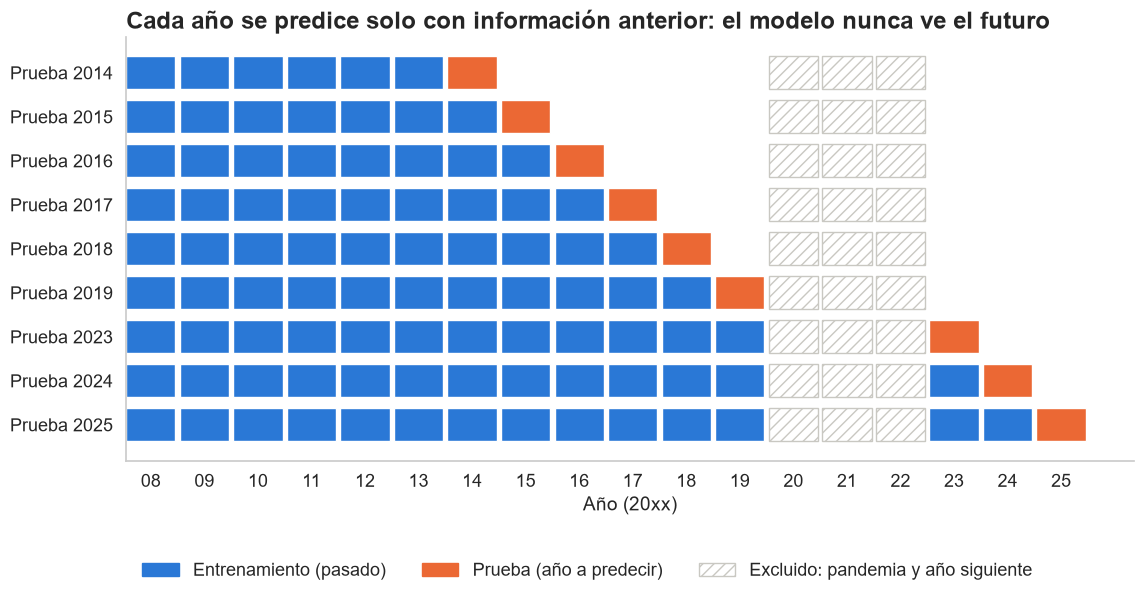

In [3]:
fig, ax = plt.subplots(figsize=(13, 5.5))
anios = np.arange(2008, 2026)
for fila, anio_test in enumerate(ANIOS_BACKTEST):
    for anio in anios:
        if 2020 <= anio <= 2022:
            color, hatch = "white", "///"
        elif anio < anio_test:
            color, hatch = AZUL, None
        elif anio == anio_test:
            color, hatch = NARANJA, None
        else:
            continue
        ax.barh(fila, 0.92, left=anio - 0.46, color=color, edgecolor=GRIS_CLARO if hatch else "white",
                hatch=hatch, height=0.75)
ax.set_yticks(range(len(ANIOS_BACKTEST)), [f"Prueba {a}" for a in ANIOS_BACKTEST])
ax.invert_yaxis()
ax.set_xticks(anios, [str(a)[2:] for a in anios])
ax.set_xlabel("Año (20xx)")
ax.grid(False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=AZUL, label="Entrenamiento (pasado)"), Patch(color=NARANJA, label="Prueba (año a predecir)"),
                   Patch(facecolor="white", edgecolor=GRIS_CLARO, hatch="///", label="Excluido: pandemia y año siguiente")],
          loc="lower left", bbox_to_anchor=(0, -0.32), ncol=3, frameon=False)
ax.set_title("Cada año se predice solo con información anterior: el modelo nunca ve el futuro")
plt.show()

## Fases 4 y 5 · Modelado y evaluación del pronóstico de demanda

Comparamos cinco modelos con el mismo esquema:

| Modelo | Idea en una línea | Rol |
|---|---|---|
| **Línea base** | Mismo mes del año anterior (variación 0) | El **piso**: lo que se haría a ojo |
| **Regresión lineal** | Cada variable suma o resta en línea recta | Interpretable y **extrapola** |
| **Árbol de decisión** | Preguntas sí/no encadenadas → reglas | **Explicar** a la gerencia |
| **Random Forest** | Promedio de 500 árboles, cada uno con datos y variables al azar (*bagging*) | **Precisión** y estabilidad |
| **Gradient Boosting** | Árboles chicos en secuencia, cada uno corrige al anterior | Alternativa de precisión |

### Resultado del *backtest*: error por año (MAPE, %)

In [4]:
tabla = pd.read_csv(PROCESSED / "backtest_mape.csv", index_col=0)
tabla.columns = [c if c == "Promedio" else int(c) for c in tabla.columns]
años = [a for a in tabla.columns if a != "Promedio"]
BASE = "Baseline (mismo mes año anterior)"
resumen = tabla.copy()
resumen["Años que le gana al baseline"] = [(tabla.loc[m, años] < tabla.loc[BASE, años]).sum() if m != BASE else np.nan
                                           for m in tabla.index]
resumen.round(1)

,2014,2015,2016,2017,2018,2019,2023,2024,2025,Promedio,Años que le gana al baseline
Random Forest,6.0,3.9,5.7,6.0,3.5,2.6,7.9,14.4,3.8,6.0,6.0
Baseline (mismo mes año anterior),4.4,4.5,5.7,7.4,5.2,4.0,5.7,14.8,4.8,6.3,NaN
Gradient Boosting,6.4,4.0,5.4,7.0,3.7,3.4,8.1,13.5,5.3,6.3,6.0
Árbol de decisión,6.2,4.5,5.5,6.8,4.2,3.5,8.1,15.4,4.7,6.6,6.0
Regresión lineal,10.9,3.4,6.3,5.5,4.1,4.2,26.9,14.4,3.9,8.9,5.0


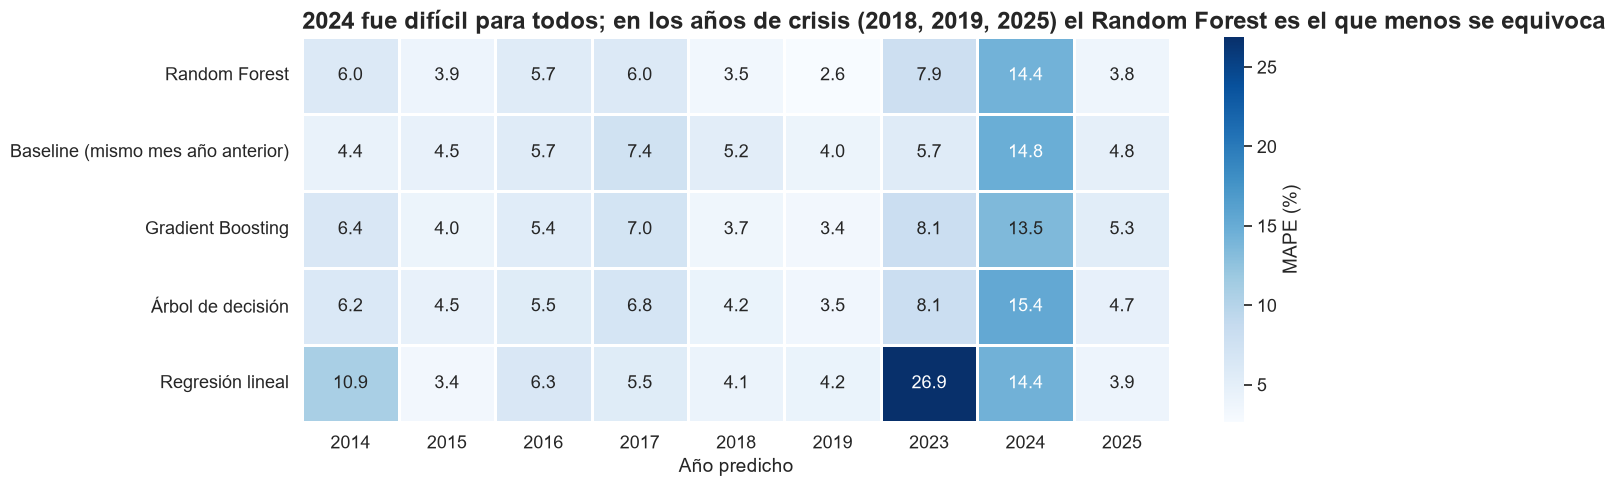

In [5]:
fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(tabla[años], annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "MAPE (%)"}, linewidths=2,
            linecolor="white", annot_kws={"size": 13}, ax=ax)
ax.set_xlabel("Año predicho"); ax.set_ylabel("")
ax.set_title("2024 fue difícil para todos; en los años de crisis (2018, 2019, 2025) el Random Forest es el que menos se equivoca")
plt.show()

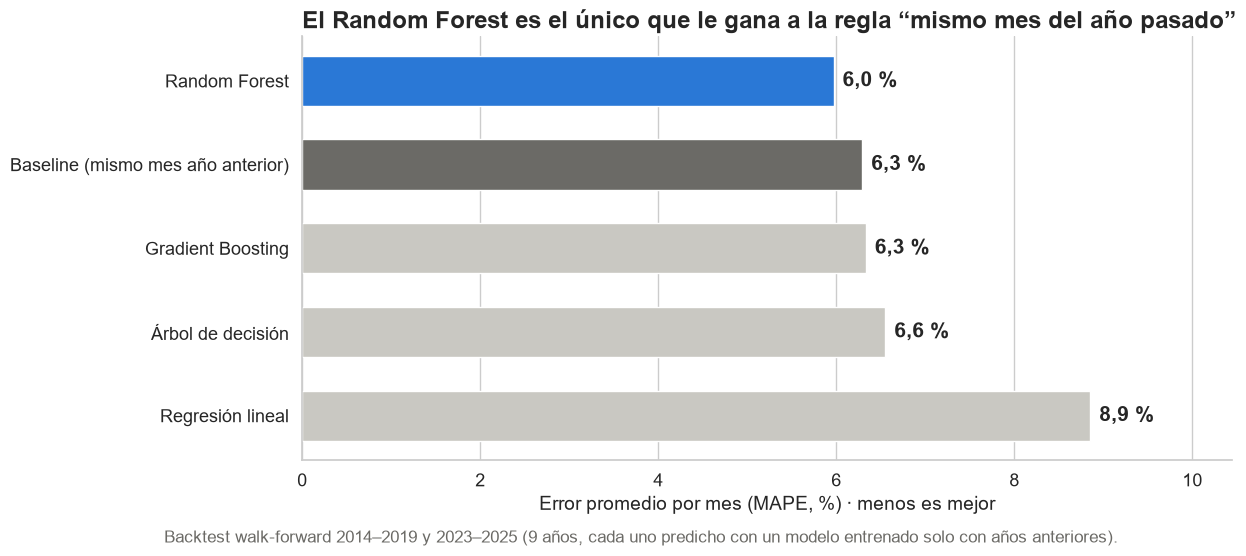

In [6]:
orden = tabla["Promedio"].sort_values()
colores = [AZUL if m == "Random Forest" else (GRIS if m == BASE else GRIS_CLARO) for m in orden.index]
fig, ax = plt.subplots(figsize=(12, 5.5))
barras = ax.barh(orden.index, orden.values, color=colores, height=0.6)
for b, v in zip(barras, orden.values):
    ax.text(v + 0.1, b.get_y() + b.get_height() / 2, pct(v), va="center", fontsize=15, fontweight="bold")
ax.invert_yaxis()
ax.set_xlabel("Error promedio por mes (MAPE, %) · menos es mejor")
ax.set_xlim(0, orden.max() * 1.18)
ax.grid(axis="y", visible=False)
ax.set_title("El Random Forest es el único que le gana a la regla “mismo mes del año pasado”")
fig.text(0.01, -0.04, "Backtest walk-forward 2014–2019 y 2023–2025 (9 años, cada uno predicho con un modelo entrenado solo con años anteriores).",
         fontsize=12, color=GRIS)
fig.savefig(IMG / "mape_por_modelo.png")
plt.show()

**Qué leemos.**

- **Random Forest: 6,0 %** de error promedio contra **6,3 %** de la línea base. Parece poco, pero le gana en **los años en que la economía se movió fuerte** (2017, 2018, 2019, 2025), que son justamente los años en que el número “a ojo” deja a la empresa con personal o cupos de más o de menos.
- **Gradient Boosting (6,3 %)** empata con la línea base: más complejo no siempre es mejor (“medir antes de complicarse”).
- **Regresión lineal (8,9 %)** es la peor en promedio por un solo año: en **2023** se equivoca 27 %. Una línea recta extrapola sin freno cuando la macro sale del rango conocido.
- **2024** (≈14 % de error en todos): la caída de la demanda fue más brusca de lo que la macro anticipaba, y además se comparaba con un 2023 inflado por PreViaje.

### Real vs. modelo vs. regla simple, 2023–2025

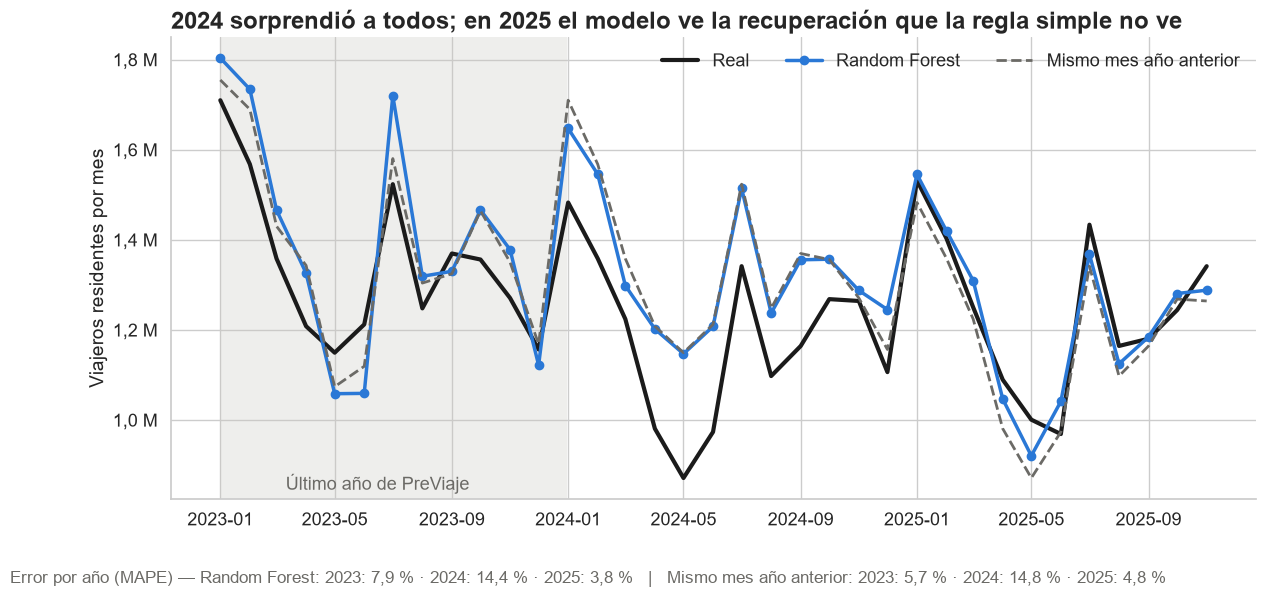

Sesgo medio (predicción vs real, %; positivo = el modelo esperaba más viajeros de los que hubo):


modelo,Random Forest,Baseline (mismo mes año anterior)
fecha,,
2023,3.5,2.7
2024,14.4,14.8
2025,-0.6,-4.4


In [7]:
preds = pd.read_csv(PROCESSED / "backtest_predicciones.csv", parse_dates=["fecha"])
ventana = preds[preds.fecha >= "2023-01-01"]
real = ventana.drop_duplicates("fecha").set_index("fecha")["real"]
rf_pred = ventana[ventana.modelo == "Random Forest"].set_index("fecha")["prediccion"]
base_pred = ventana[ventana.modelo == BASE].set_index("fecha")["prediccion"]

fig, ax = plt.subplots(figsize=(14, 6))
ax.axvspan(pd.Timestamp("2023-01-01"), pd.Timestamp("2023-12-31"), color=GRIS_CLARO, alpha=0.3, lw=0)
ax.text(pd.Timestamp("2023-06-15"), real.min() * 0.97, "Último año de PreViaje", fontsize=13, color=GRIS, ha="center")
ax.plot(real.index, real, color="#1b1b1b", lw=3, label="Real")
ax.plot(rf_pred.index, rf_pred, color=AZUL, lw=2.5, marker="o", ms=6, label="Random Forest")
ax.plot(base_pred.index, base_pred, color=GRIS, lw=2, ls="--", label="Mismo mes año anterior")
ax.yaxis.set_major_formatter(fmt_millones)
ax.set_ylabel("Viajeros residentes por mes")
ax.legend(loc="upper right", ncol=3, frameon=False)
err_rf = {a: tabla.loc["Random Forest", a] for a in [2023, 2024, 2025]}
err_bl = {a: tabla.loc[BASE, a] for a in [2023, 2024, 2025]}
ax.set_title("2024 sorprendió a todos; en 2025 el modelo ve la recuperación que la regla simple no ve")
fig.text(0.01, -0.03, "Error por año (MAPE) — Random Forest: " + " · ".join(f"{a}: {pct(err_rf[a])}" for a in err_rf)
         + "   |   Mismo mes año anterior: " + " · ".join(f"{a}: {pct(err_bl[a])}" for a in err_bl),
         fontsize=12, color=GRIS)
fig.savefig(IMG / "real_vs_modelo_2023_2025.png")
plt.show()

sesgo = ((ventana.prediccion / ventana.real - 1) * 100).groupby([ventana.fecha.dt.year, ventana.modelo]).mean().unstack()
print("Sesgo medio (predicción vs real, %; positivo = el modelo esperaba más viajeros de los que hubo):")
sesgo[["Random Forest", BASE]].round(1)

**Qué leemos.** En **2023 y 2024** ambos esperaban **más** viajeros de los que hubo: el punto de partida (2022 y 2023) estaba inflado por el rebote post-pandemia y por **PreViaje**, un subsidio que la macro no ve. En **2025** la regla simple se queda corta (esperaba menos viajeros que los reales) y el Random Forest casi no tiene sesgo: leyó la recuperación del salario real.

### Árbol de decisión: ¿qué profundidad?

Un árbol más profundo memoriza mejor el pasado (el error de entrenamiento baja siempre), pero a partir de cierto punto **empeora al predecir años nuevos**: eso es *overfitting*. Elegimos la profundidad **con el gráfico, no con la intuición**: la que da menor error en los años de prueba.

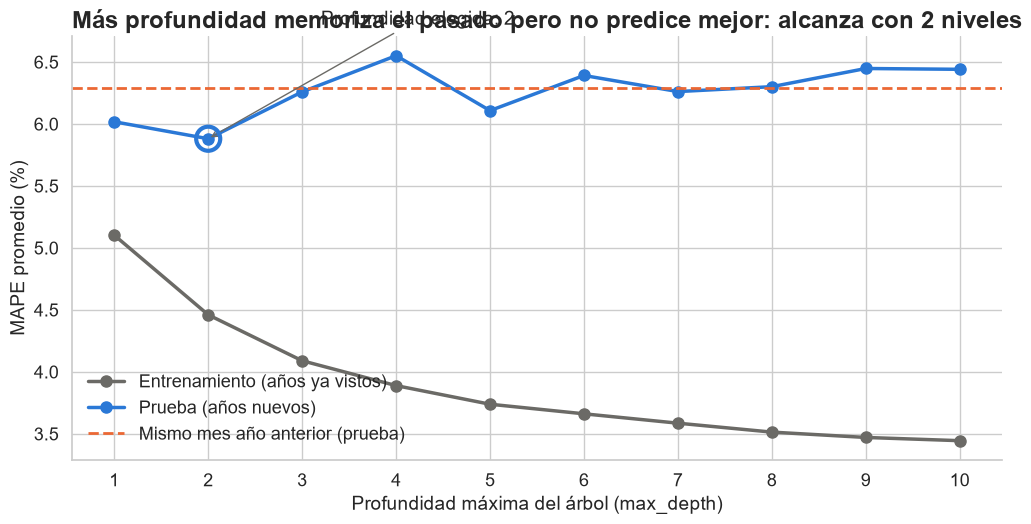

profundidad,1,2,3,4,5,6,7,8,9,10
Entrenamiento,5.10,4.46,4.09,3.89,3.74,3.66,3.59,3.51,3.47,3.44
Prueba,6.02,5.88,6.26,6.55,6.11,6.39,6.26,6.30,6.45,6.44


In [8]:
def curva_profundidad(profundidades):
    filas = []
    for p in profundidades:
        for anio in ANIOS_BACKTEST:
            train, test = d[d.index.year < anio], d[d.index.year == anio]
            m = DecisionTreeRegressor(max_depth=p, min_samples_leaf=5, random_state=SEMILLA)
            m.fit(train[FEATURES], train.var_viajeros)
            filas.append({"profundidad": p, "anio": anio,
                          "Entrenamiento": mape(train[TARGET], a_viajeros(train, m.predict(train[FEATURES]))),
                          "Prueba": mape(test[TARGET], a_viajeros(test, m.predict(test[FEATURES])))})
    return pd.DataFrame(filas)

curva_det = curva_profundidad(range(1, 11))
curva = curva_det.groupby("profundidad")[["Entrenamiento", "Prueba"]].mean()
PROF = int(curva["Prueba"].idxmin())

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(curva.index, curva["Entrenamiento"], color=GRIS, lw=2.5, marker="o", ms=8, label="Entrenamiento (años ya vistos)")
ax.plot(curva.index, curva["Prueba"], color=AZUL, lw=2.5, marker="o", ms=8, label="Prueba (años nuevos)")
ax.axhline(tabla.loc[BASE, "Promedio"], color=NARANJA, ls="--", lw=2, label="Mismo mes año anterior (prueba)")
ax.scatter([PROF], [curva.loc[PROF, "Prueba"]], s=300, facecolor="none", edgecolor=AZUL, lw=3, zorder=5)
ax.annotate(f"Profundidad elegida: {PROF}", (PROF, curva.loc[PROF, "Prueba"]), xytext=(PROF + 1.2, curva["Prueba"].max() + 0.25),
            fontsize=14, arrowprops=dict(arrowstyle="->", color=GRIS))
ax.set_xlabel("Profundidad máxima del árbol (max_depth)")
ax.set_ylabel("MAPE promedio (%)")
ax.set_xticks(curva.index)
ax.legend(frameon=False, loc="lower left")
ax.set_title(f"Más profundidad memoriza el pasado pero no predice mejor: alcanza con {PROF} niveles")
plt.show()
curva.round(2).T

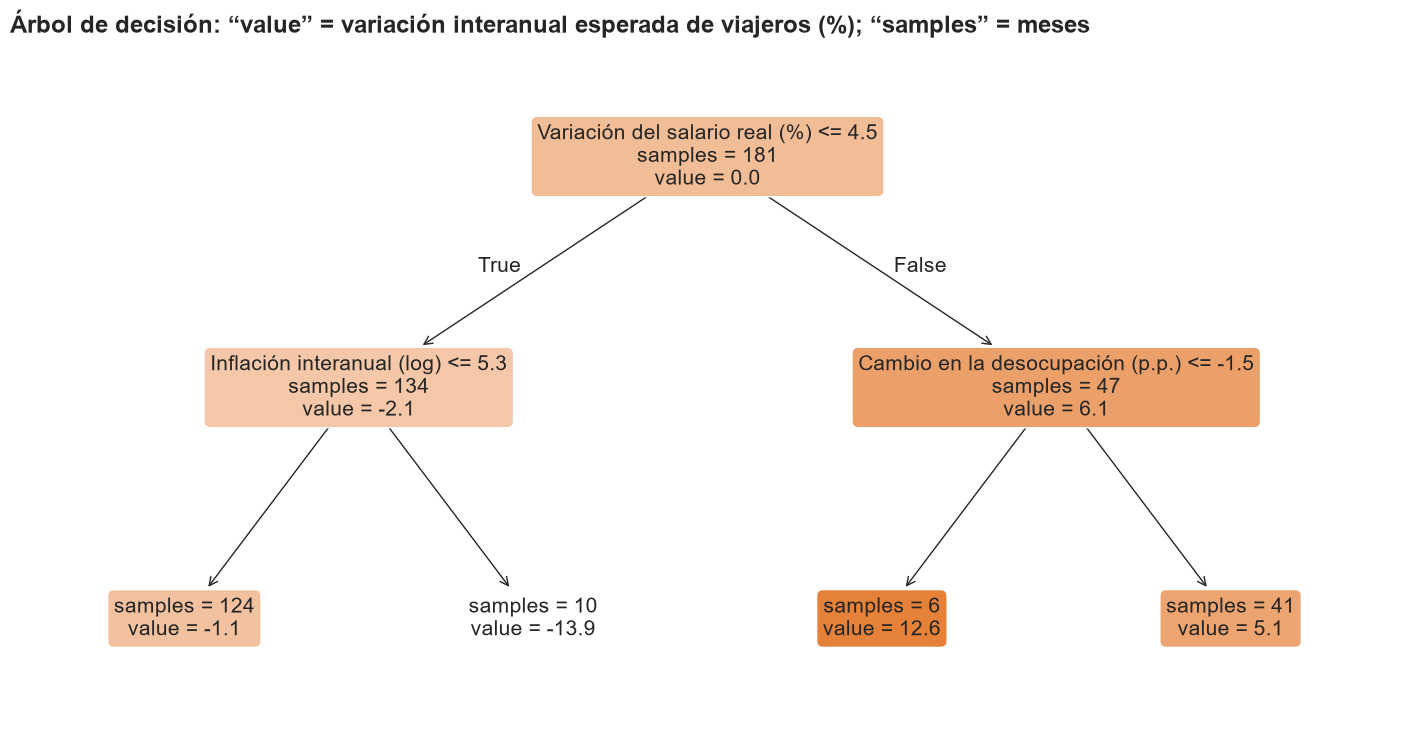

In [9]:
arbol = DecisionTreeRegressor(max_depth=PROF, min_samples_leaf=5, random_state=SEMILLA).fit(d[FEATURES], d.var_viajeros)
fig, ax = plt.subplots(figsize=(18, 4 + 2.5 * PROF))
plot_tree(arbol, feature_names=[NOMBRES[f] for f in FEATURES], filled=True, rounded=True, precision=1,
          impurity=False, fontsize=15 if PROF <= 2 else 12, ax=ax)
ax.set_title("Árbol de decisión: “value” = variación interanual esperada de viajeros (%); “samples” = meses", fontsize=17)
plt.show()

In [10]:
MESES = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto", "septiembre", "octubre",
         "noviembre", "diciembre"]

def hojas(arbol, columnas):
    """Recorre el árbol y devuelve, por hoja, el intervalo (desde, hasta] de cada variable usada."""
    t = arbol.tree_
    salida = []
    def recorrer(nodo, condiciones):
        if t.children_left[nodo] == -1:
            salida.append((nodo, condiciones)); return
        f, u = columnas[t.feature[nodo]], t.threshold[nodo]
        lo, hi = condiciones.get(f, (-np.inf, np.inf))
        recorrer(t.children_left[nodo], {**condiciones, f: (lo, min(hi, u))})
        recorrer(t.children_right[nodo], {**condiciones, f: (max(lo, u), hi)})
    recorrer(0, {})
    return salida

def num(x):
    return f"{x:.1f}".replace(".", ",")

def condicion_demanda(f, lo, hi):
    if f == "mes":
        m = [MESES[i - 1] for i in range(1, 13) if lo < i <= hi]
        return f"el mes es de {m[0]} a {m[-1]}"
    if f == "inflacion_log":
        lo, hi = (v if np.isinf(v) else np.expm1(v) for v in (lo, hi))
        nombre = "la inflación interanual"
    else:
        nombre = NOMBRES[f].split(" (")[0].lower().replace("variación", "la variación").replace("cambio", "el cambio").replace("actividad", "la actividad")
    unidad = " p.p." if f == "desocupacion_var" else " %"
    if np.isinf(lo):
        return f"{nombre} es ≤ {num(hi)}{unidad}"
    if np.isinf(hi):
        return f"{nombre} es > {num(lo)}{unidad}"
    return f"{nombre} está entre {num(lo)} y {num(hi)}{unidad}"

filas = []
for nodo, cond in hojas(arbol, FEATURES):
    valor = arbol.tree_.value[nodo][0][0]
    filas.append({"Regla (si … entonces …)": "Si " + " y ".join(condicion_demanda(f, *v) for f, v in cond.items())
                  + f" → los viajeros {'crecen' if valor >= 0 else 'caen'} {num(abs(valor))} % contra el mismo mes del año anterior",
                  "Meses históricos": arbol.tree_.n_node_samples[nodo]})
reglas_demanda = pd.DataFrame(filas).sort_values("Meses históricos", ascending=False)
with pd.option_context("display.max_colwidth", None):
    display(reglas_demanda.style.hide(axis="index").set_properties(**{"text-align": "left", "font-size": "14px"}))

Regla (si … entonces …),Meses históricos
"Si la variación del salario real es ≤ 4,5 % y la inflación interanual es ≤ 200,8 % → los viajeros caen 1,1 % contra el mismo mes del año anterior",124
"Si la variación del salario real es > 4,5 % y el cambio en la desocupación es > -1,5 p.p. → los viajeros crecen 5,1 % contra el mismo mes del año anterior",41
"Si la variación del salario real es ≤ 4,5 % y la inflación interanual es > 200,8 % → los viajeros caen 13,9 % contra el mismo mes del año anterior",10
"Si la variación del salario real es > 4,5 % y el cambio en la desocupación es ≤ -1,5 p.p. → los viajeros crecen 12,6 % contra el mismo mes del año anterior",6


**Qué leemos.** El árbol resume la historia en pocas reglas que cualquier gerente puede chequear con el diario: **la variable que más separa es el salario real** y, cuando el salario no crece, **la inflación alta** marca los años de caída. Es el modelo que usamos para **explicar**; para **predecir** usamos el Random Forest (ver comparación más abajo).

### Random Forest: validación *out-of-bag* e importancia de variables

Cada uno de los 500 árboles se entrena con una muestra al azar de los meses (*bootstrap*); los meses que le quedaron afuera (≈37 %) sirven para medirlo gratis: es el **OOB score**. El conjunto de prueba sigue siendo el *backtest*.

In [11]:
rf = cargar("demanda_rf.joblib")  # entrenado con todos los meses utilizables (src/entrenar.py)
nivel_oob = a_viajeros(d, rf.oob_prediction_)
print(f"Árboles: {rf.n_estimators} · meses de entrenamiento: {len(d)}")
print(f"OOB R² sobre la variación interanual: {rf.oob_score_:.2f}  "
      f"(explica ~{rf.oob_score_:.0%} de las subidas y bajadas interanuales en meses que cada árbol no vio)")
print(f"OOB MAPE en viajeros: {pct(mape(d[TARGET], nivel_oob))}  vs.  mismo mes año anterior: "
      f"{pct(mape(d[TARGET], d.viajeros_anio_anterior))}")

Árboles: 500 · meses de entrenamiento: 181
OOB R² sobre la variación interanual: 0.37  (explica ~37% de las subidas y bajadas interanuales en meses que cada árbol no vio)
OOB MAPE en viajeros: 4,7 %  vs.  mismo mes año anterior: 6,1 %


**Importancia por permutación** (no la importancia “MDI” que trae el modelo, que favorece a variables con muchos valores distintos): en cada año de prueba **desordenamos una variable** y medimos cuánto empeora el error. Si empeora mucho, el modelo depende de esa variable. Se promedia sobre los 9 años del *backtest*, siempre con datos que el modelo no vio.

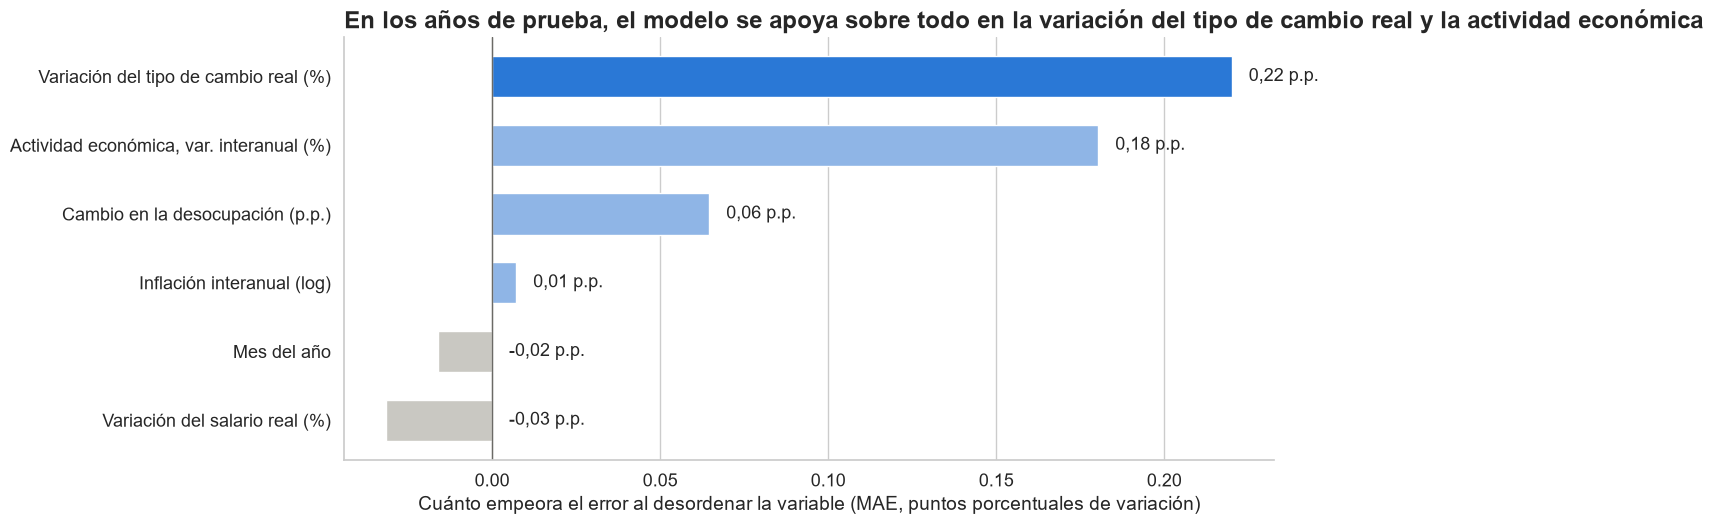

,Mes del año,Variación del salario real (%),Inflación interanual (log),Cambio en la desocupación (p.p.),Variación del tipo de cambio real (%),"Actividad económica, var. interanual (%)"
2014,-0.00,0.00,0.00,0.25,0.05,-0.02
2015,-0.03,0.17,0.14,0.46,0.09,0.21
2016,-0.04,-0.01,-0.06,0.11,0.02,-0.13
2017,0.17,0.08,0.02,-0.04,0.06,0.11
2018,-0.26,-0.34,-0.24,0.07,0.73,1.65
2019,0.01,-0.06,0.00,-0.07,0.61,1.07
2023,-0.03,-0.41,0.00,-0.11,-0.27,-1.34
2024,0.09,-0.28,0.02,-0.08,-0.09,0.08
2025,-0.05,0.57,0.19,-0.00,0.79,-0.01


In [12]:
importancias, arboles_gb = [], {}
for anio in ANIOS_BACKTEST:
    train, test = d[d.index.year < anio], d[d.index.year == anio]
    modelos = modelos_demanda()
    m = modelos["Random Forest"].fit(train[FEATURES], train.var_viajeros)
    r = permutation_importance(m, test[FEATURES], test.var_viajeros, n_repeats=20, random_state=SEMILLA,
                               scoring="neg_mean_absolute_error")
    importancias.append(pd.Series(r.importances_mean, index=FEATURES, name=anio))
    arboles_gb[anio] = modelos["Gradient Boosting"].fit(train[FEATURES], train.var_viajeros).n_estimators_
imp = pd.concat(importancias, axis=1)
imp_media = imp.mean(axis=1).sort_values()

fig, ax = plt.subplots(figsize=(12, 5.5))
colores = [AZUL if v == imp_media.max() else (GRIS_CLARO if v <= 0 else "#8fb5e6") for v in imp_media]
ax.barh([NOMBRES[f] for f in imp_media.index], imp_media.values, color=colores, height=0.6)
for i, v in enumerate(imp_media.values):
    ax.text(max(v, 0) + 0.005, i, f"{v:.2f}".replace(".", ",") + " p.p.", va="center", fontsize=13)
ax.axvline(0, color=GRIS, lw=1)
ax.set_xlabel("Cuánto empeora el error al desordenar la variable (MAE, puntos porcentuales de variación)")
ax.grid(axis="y", visible=False)
corto = {f: NOMBRES[f].split(",")[0].split(" (")[0].lower() for f in FEATURES}
ax.set_title(f"En los años de prueba, el modelo se apoya sobre todo en la {corto[imp_media.index[-1]]} y la {corto[imp_media.index[-2]]}")
plt.show()
(imp.T.rename(columns=NOMBRES)).round(2)

**Lectura de negocio.** Cuando hay que anticipar un año nuevo, las señales que más usa el modelo son **el tipo de cambio real (las devaluaciones) y la actividad económica**: son las que le permitieron ver venir las caídas de 2018–2019 y la recuperación de 2025 (ver la tabla por año). El salario real es el primer corte del árbol, pero en prueba su información se superpone con la del dólar: cada devaluación fuerte vino con caída del salario real, y el modelo puede usar cualquiera de las dos. La importancia **cambia mucho de un año a otro**: en 2023 desordenar la actividad hasta *mejora* el error, porque ese año la demanda la movió PreViaje y no la economía. **Ojo: esto no es causal ni tiene signo.** Dice “sin esta variable el modelo predice peor”, no “si sube el salario, sube la demanda en tal cantidad” (para eso está la regresión lineal y el análisis de sensibilidad del notebook 03). Variables que se mueven juntas (salario, inflación, desocupación) se “reparten” la importancia.

### Gradient Boosting con *early stopping*

El *boosting* agrega árboles chicos (profundidad 3) en secuencia. Si se lo deja, sigue agregando hasta memorizar el ruido; con ***early stopping*** se reserva el 20 % del entrenamiento y se frena cuando 50 árboles seguidos no mejoran ese 20 %.

In [13]:
gb_final = modelos_demanda()["Gradient Boosting"].fit(d[FEATURES], d.var_viajeros)
arboles = pd.Series({**arboles_gb, "Modelo final (todos los años)": gb_final.n_estimators_}, name="Árboles usados de 1.000 posibles")
print(f"El early stopping frenó entre {min(arboles_gb.values())} y {max(arboles_gb.values())} árboles según el año: "
      "nunca necesitó los 1.000.")
arboles.to_frame().T

El early stopping frenó entre 66 y 172 árboles según el año: nunca necesitó los 1.000.


,2014,2015,2016,2017,2018,2019,2023,2024,2025,Modelo final (todos los años)
Árboles usados de 1.000 posibles,99,66,153,172,73,74,172,162,149,342


**Qué leemos.** Con *early stopping* el *boosting* no sobreajusta, pero igual queda en **6,3 %**, empatado con la regla simple. Con ~180 meses de historia, la diferencia entre *ensembles* cae dentro del ruido: no vale la pena complicarse más.

### Regresión lineal: el complemento interpretable

La regresión lineal tiene más error, pero dice **para qué lado y cuánto** mueve cada variable, en unidades que se entienden. (Los coeficientes de los meses solo capturan diferencias de estacionalidad y se omiten.)

In [14]:
lineal = modelos_demanda()["Regresión lineal"].fit(d[FEATURES], d.var_viajeros)
macro = FEATURES[1:]
escala = lineal[0].named_transformers_["remainder"].scale_
coef = pd.Series(lineal[-1].coef_[-len(macro):], index=macro) / escala  # por unidad original
cambios = {"salario_real_var": (1, "El salario real crece 1 % más"),
           "inflacion_log": (np.log(2), "La inflación interanual se duplica (ej. 30 % → 60 %)"),
           "desocupacion_var": (1, "La desocupación sube 1 punto"),
           "tipo_cambio_real_var": (10, "El dólar real sube 10 %"),
           "emae_interanual": (1, "La actividad crece 1 punto más")}
coeficientes = pd.DataFrame([{"Si…": txt, "…la variación de viajeros cambia (p.p.)": round(coef[f] * u, 2)}
                             for f, (u, txt) in cambios.items()])
coeficientes

,Si…,…la variación de viajeros cambia (p.p.)
0,El salario real crece 1 % más,0.29
1,La inflación interanual se duplica (ej. 30 % →...,-1.01
2,La desocupación sube 1 punto,-1.73
3,El dólar real sube 10 %,0.75
4,La actividad crece 1 punto más,0.45


**Qué leemos.** Los signos son los que espera cualquiera que conozca el negocio: **más salario real y más actividad → más viajeros; más inflación y más desocupación → menos**. Un dólar real más caro empuja algo de demanda hacia el turismo interno (viajar afuera se encarece). Esto le da credibilidad al modelo de árboles, que llega a conclusiones parecidas por otro camino.

## ¿Por qué Random Forest y no otro?

In [15]:
arbol_prof = curva_det[curva_det.profundidad == PROF].set_index("anio")["Prueba"]
comp = tabla[años].copy()
comp.loc[f"Árbol de decisión (profundidad {PROF}, de la curva)"] = arbol_prof.reindex(años).values
comparacion = pd.DataFrame({
    "MAPE promedio (%)": comp.mean(axis=1),
    "Peor año (%)": comp.max(axis=1),
    "Desvío entre años (p.p.)": comp.std(axis=1),
    "Años que le gana al baseline (de 9)": [(comp.loc[m] < comp.loc[BASE]).sum() for m in comp.index],
})
comparacion.loc[BASE, "Años que le gana al baseline (de 9)"] = np.nan
rol = {"Random Forest": "Pronóstico (elegido)", "Gradient Boosting": "Descartado: más complejo, no mejora",
       "Árbol de decisión": "Explicar con reglas", BASE: "Piso de comparación", "Regresión lineal": "Signos y extrapolación",
       f"Árbol de decisión (profundidad {PROF}, de la curva)": "Explicar con reglas"}
comparacion["Rol"] = [rol[m] for m in comparacion.index]
comparacion.sort_values("MAPE promedio (%)").round(1)

,MAPE promedio (%),Peor año (%),Desvío entre años (p.p.),Años que le gana al baseline (de 9),Rol
"Árbol de decisión (profundidad 2, de la curva)",5.9,14.3,3.4,6.0,Explicar con reglas
Random Forest,6.0,14.4,3.6,6.0,Pronóstico (elegido)
Baseline (mismo mes año anterior),6.3,14.8,3.4,NaN,Piso de comparación
Gradient Boosting,6.3,13.5,3.1,6.0,"Descartado: más complejo, no mejora"
Árbol de decisión,6.6,15.4,3.6,6.0,Explicar con reglas
Regresión lineal,8.9,26.9,7.7,5.0,Signos y extrapolación


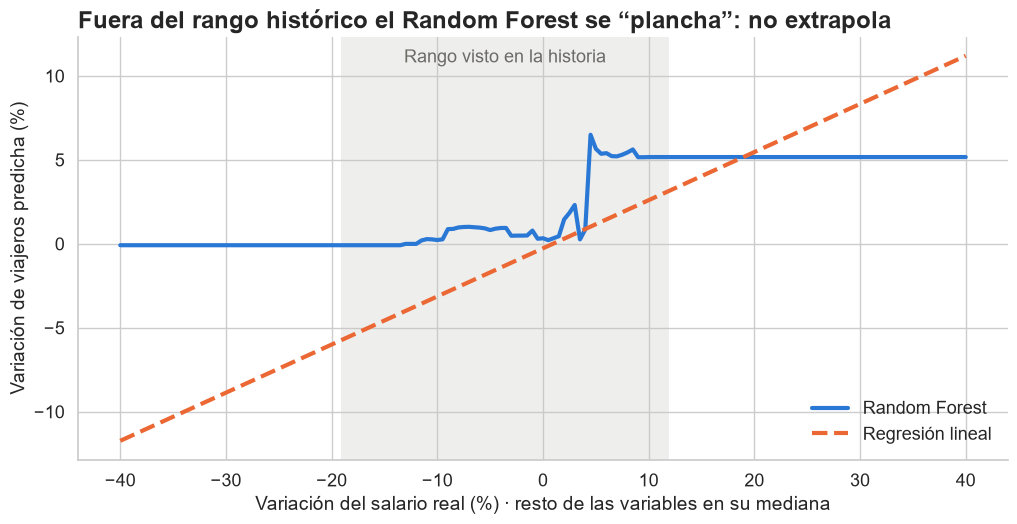

In [16]:
# Los árboles no extrapolan: qué predice cada modelo si el salario real se sale del rango histórico
grilla = pd.DataFrame({f: d[f].median() for f in FEATURES}, index=range(161))
grilla["mes"] = 1
grilla["salario_real_var"] = np.linspace(-40, 40, 161)
fig, ax = plt.subplots(figsize=(12, 5.5))
lo, hi = d.salario_real_var.min(), d.salario_real_var.max()
ax.axvspan(lo, hi, color=GRIS_CLARO, alpha=0.3, lw=0)
ax.text((lo + hi) / 2, 0.97, "Rango visto en la historia", transform=ax.get_xaxis_transform(), ha="center", va="top",
        fontsize=13, color=GRIS)
ax.plot(grilla.salario_real_var, rf.predict(grilla[FEATURES]), color=AZUL, lw=3, label="Random Forest")
ax.plot(grilla.salario_real_var, lineal.predict(grilla[FEATURES]), color=NARANJA, lw=3, ls="--", label="Regresión lineal")
ax.set_xlabel("Variación del salario real (%) · resto de las variables en su mediana")
ax.set_ylabel("Variación de viajeros predicha (%)")
ax.legend(frameon=False, loc="lower right")
ax.set_title("Fuera del rango histórico el Random Forest se “plancha”: no extrapola")
plt.show()

**La decisión, en términos de negocio:**

1. **Le gana a la regla simple** en promedio y, sobre todo, **en los años de crisis**, que es cuando un error de planificación cuesta más (personal contratado de más, cupos sin vender o, al revés, demanda que no se puede atender).
2. **Es estable**: no depende de un único corte como el árbol. El árbol podado a 2 niveles tiene un error parecido (5,9 %, algo optimista porque su profundidad se eligió mirando esos mismos años), pero un árbol cambia mucho si se agregan unos pocos meses (es *inestable*); el promedio de 500 árboles no.
3. **No necesita supuestos de línea recta**: capta efectos que se activan solo pasado un umbral (por ejemplo, la inflación hace daño cuando se dispara).
4. **Su limitación está acotada por diseño**: no extrapola fuera del rango histórico, pero como predecimos **variaciones** (que sí se mantienen en rango) y no niveles, eso no lo afecta en escenarios razonables. Para escenarios extremos, se contrasta con la **regresión lineal**, que sí extrapola.

**Qué aporta cada modelo** (combinar y justificar): la **línea base** es el piso; el **Random Forest** da el número; el **árbol** da las reglas para contarlo; la **regresión lineal** da los signos y el chequeo en escenarios extremos; el **boosting** confirma que complicarse más no mejora.


---

## Demanda por región: el modelo de Tina, corregido

El RF nacional proyecta el total del país, pero un hotel necesita **su región**. El modelo regional oficial es el del notebook de Tina (`00_tina_datamart.ipynb`): un solo modelo para las **7 regiones de la EOH**, con la región en *one-hot*, el mes en seno y coseno y los vuelos de la ANAC. Su pipeline está en `src/preparar_datos.py` (`dataset_region`) y el modelo en `src/modelos.py`. `00_tina_datamart.ipynb` es su versión, sin cambios nuestros. Su versión actual ya usa **solo vuelos de cabotaje**, **corta entrenamiento y prueba por fecha** (entrena hasta 2022 y prueba desde 2023) y **documenta la pérdida de 2012–2016**. Lo que hacemos distinto, y por qué:

1. **Random Forest en lugar de Gradient Boosting** (el GB, con sus hiperparámetros, queda como modelo comparado).
2. **Validación año por año**: el mismo *backtest* del modelo nacional (9 años de prueba; cada uno se predice entrenando solo con los años anteriores), en lugar de un único corte. Con el gasto EVyTH hasta 2024-T2, su prueba son 18 meses (2023 a 2024-T2), y un solo corte depende mucho de lo que pasó en ese período.
3. **Siempre contra el baseline** "mismo mes del año anterior" **de cada región**: su versión informa R² y MAE, pero no compara contra la regla simple, que es lo que haría una empresa sin modelo.
4. **Variación interanual en lugar del nivel** (ver abajo).
5. **Vuelos con 12 meses de rezago.** Su versión usa los vuelos del mismo mes, que no se conocen cuando se pronostica. Con el rezago, el pronóstico de un mes usa los vuelos de un año antes, que ya están publicados: por eso el modelo puede **anticipar** sin suponer vuelos futuros. La ANAC llega a 2026-07, así que los pronósticos hasta 2027-07 usan vuelos observados.
6. **Solo viajeros residentes** (ella suma residentes y no residentes), como el modelo nacional, y pandemia excluida igual que en el nacional.
7. **No incorporamos `cluster_perfil`.** En su versión, el perfil del K-Means entra al modelo como *dummy* (R² 0,87, MAE ≈ 27 mil viajeros). Pero el K-Means se calcula con **`viajeros`, que es justamente lo que se quiere predecir**, y se ajusta con todos los meses, también los de prueba: la *dummy* le pasa al modelo información del resultado (*leakage*). Al pronosticar un mes futuro no se conoce su cantidad de viajeros, así que tampoco su perfil. Por eso ese R² no es comparable con nuestro *backtest*, y el K-Means queda en el EDA como análisis descriptivo: **no es una variable de nuestro modelo**.

In [17]:
from modelos import (FEATURES_REGION, REGIONES, cargar_region, modelos_region, pipeline_region, proyectar_region,
                     x_futuro_region)
import precios

dfr = cargar_region()
u_r = utilizables(dfr)
cobertura = pd.DataFrame({
    "Filas (mes × región)": [len(u_r), u_r.pasajeros_var_l12.notna().sum(), u_r.gasto_usd.notna().sum(),
                             u_r.gasto_usd_var.notna().sum()],
    "Años": [f"{u_r.index.year.min()}–{u_r.index.year.max()}",
             ", ".join(map(str, sorted(set(u_r[u_r.pasajeros_var_l12.notna()].index.year)))),
             f"{u_r[u_r.gasto_usd.notna()].index.year.min()}–{u_r[u_r.gasto_usd.notna()].index.year.max()}",
             f"{u_r[u_r.gasto_usd_var.notna()].index.year.min()}–{u_r[u_r.gasto_usd_var.notna()].index.year.max()}"],
}, index=["Meses utilizables para entrenar", "…con vuelos (var. interanual, rezago 12)", "…con gasto EVyTH observado",
          "…con variación del gasto (repitiendo la última después de 2024-T2)"])
cobertura

,Filas (mes × región),Años
Meses utilizables para entrenar,1267,2008–2025
"…con vuelos (var. interanual, rezago 12)",259,"2019, 2020, 2024, 2025"
…con gasto EVyTH observado,812,2012–2024
…con variación del gasto (repitiendo la última después de 2024-T2),847,2013–2025


**Cobertura: los años sin vuelos ni gasto.** El modelo usa **todos** los meses utilizables (2008–2025, sin pandemia), no solo los que tienen vuelos. Los vuelos empiezan en 2017; su variación interanual, en 2018, y con el rezago de 12 meses recién hay dato en 2019 (2023 tampoco tiene: se compara con 2022, que a su vez se compara con la pandemia). Así, solo **259 de 1.267 filas (20 %)** tienen el dato de vuelos: **2019, enero–febrero de 2020, 2024 y 2025**. En las demás, el faltante se completa con **0** (variación nula) dentro del *pipeline* (`SimpleImputer`), así que los años 2008–2018 y 2023 entrenan igual con la región y el mes, y los vuelos solo pueden aprender de esos 3 años y pico. El **gasto EVyTH** cubre 2012 a 2024-T2 (812 filas); como candidato se usa su variación interanual, que se repite después de 2024-T2 y vale 0 antes de 2013. En el notebook de Tina, el `dropna` sobre vuelos y gasto deja el data mart en 2017 a 2024-T2 (ella documenta esa pérdida); acá, en cambio, se entrena con 2008–2025 y los faltantes se completan con 0.

In [18]:
mape_reg = pd.read_csv(PROCESSED / "backtest_region_mape.csv", header=[0, 1], index_col=0)
BASE_R = "Baseline (mismo mes año anterior)"
resumen_reg = mape_reg.loc["Promedio"].unstack("modelo")[[BASE_R, "Random Forest", "Gradient Boosting"]]
resumen_reg.index.name = "Versión"
resumen_reg.round(2)

modelo,Baseline (mismo mes año anterior),Random Forest,Gradient Boosting
Versión,,,
Final (con selección de variables),9.12,9.01,10.05
Tina + 5 macro,9.12,9.11,10.10
Tina corregida (nivel),9.12,11.91,12.35
Tina corregida (variación),9.12,9.56,9.70


**Nivel o variación.** La versión de Tina predice la **cantidad** de viajeros. Con la validación por año completo, predecir el nivel da **11,9 %** de error promedio (RF), mucho peor que repetir el año anterior (9,1 %): los árboles no extrapolan y cada región tiene su propia tendencia. Prediciendo la **variación interanual** (como el modelo nacional) baja a **9,6 %**, porque el nivel y la estacionalidad de cada región los pone el "mismo mes del año anterior" y el modelo solo estima el cambio. **Usamos la variación.**

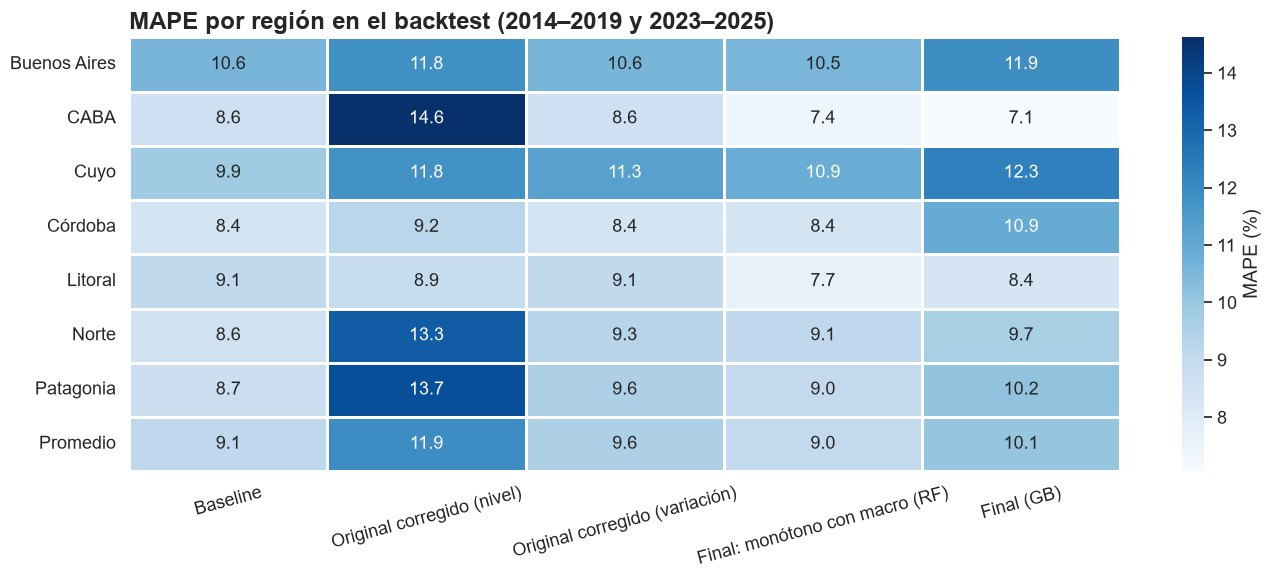

In [19]:
tabla_reg = pd.DataFrame({
    "Baseline": mape_reg[("Final (con selección de variables)", BASE_R)],
    "Original corregido (nivel)": mape_reg[("Tina corregida (nivel)", "Random Forest")],
    "Original corregido (variación)": mape_reg[("Tina corregida (variación)", "Random Forest")],
    "Final: monótono con macro (RF)": mape_reg[("Final (con selección de variables)", "Random Forest")],
    "Final (GB)": mape_reg[("Final (con selección de variables)", "Gradient Boosting")],
})
fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(tabla_reg, annot=True, fmt=".1f", cmap="Blues", linewidths=2, linecolor="white",
            cbar_kws={"label": "MAPE (%)"}, annot_kws={"size": 13}, ax=ax)
ax.set(title="MAPE por región en el backtest (2014–2019 y 2023–2025)", xlabel="", ylabel="")
ax.tick_params(axis="x", rotation=15)
ax.grid(False)
plt.tight_layout(); plt.show()

In [20]:
seleccion = pd.read_csv(PROCESSED / "seleccion_variables_region.csv")
seleccion.columns = ["Variable que se suma", "MAPE promedio (%)", "¿Queda?"]
seleccion.round(2)

,Variable que se suma,MAPE promedio (%),¿Queda?
0,(base de Tina),9.56,True
1,salario_real_var,9.38,True
2,inflacion_log,9.28,True
3,desocupacion_var,9.37,False
4,tipo_cambio_real_var,10.25,False
5,emae_interanual,9.01,True
6,gasto_usd_var,9.01,False
7,"bloque macro (salario_real_var, inflacion_log,...",9.11,False


**Qué leemos.**

- **Selección de variables** (sobre la versión de Tina con nuestras correcciones, 9,56 %; cada candidata queda solo si baja el MAPE, y al final se prueba también el bloque macro completo). Con las restricciones de monotonía (ver abajo), entran **salario real (9,38 %)**, **inflación (9,28 %)** y **actividad / EMAE (9,01 %)**. No entran la desocupación (9,37 %), el tipo de cambio real (10,25 %), el gasto en USD (9,015 %, no baja del 9,010 %) ni el bloque completo (9,11 %).
- El modelo final **le gana por poco a la regla simple**: **9,01 % contra 9,12 %**. Gana en **CABA (7,4 % contra 8,6 %)** y **Litoral (7,7 % contra 9,1 %)**, empata en Buenos Aires y Córdoba, y pierde en Cuyo (10,9 % contra 9,9 %), Norte (9,1 % contra 8,6 %) y Patagonia (9,1 % contra 8,7 %).
- El **Gradient Boosting**, con los hiperparámetros de Tina, queda peor que el RF (10,1 %).

### Restricciones de monotonía

Sin restricciones, un Random Forest puede aprender relaciones con el signo cambiado en algún tramo (por ejemplo, "menos inflación → menos viajeros" en una región), y eso desordenaba los escenarios. Con `monotonic_cst` de scikit-learn se le exige al RF regional que la demanda **no baje cuando sube el salario real o la actividad (+1)** y **no suba cuando sube la inflación o la desocupación (−1)**; el tipo de cambio real, la región, el mes y los vuelos quedan libres (0).

| Región | Baseline | RF con las 5 macro, sin restricciones | RF monótono (final) |
|---|---|---|---|
| Buenos Aires | 10,58 | 11,01 | 10,54 |
| CABA | 8,64 | 7,40 | 7,40 |
| Cuyo | 9,86 | 10,98 | 10,89 |
| Córdoba | 8,42 | 9,32 | 8,42 |
| Litoral | 9,07 | 8,56 | 7,65 |
| Norte | 8,56 | 9,14 | 9,11 |
| Patagonia | 8,71 | 9,04 | 9,05 |
| **Promedio** | **9,12** | **9,35** | **9,01** |

Las restricciones **bajan el error** (9,35 % → 9,01 %) y ordenan los escenarios (abajo). Para el **modelo nacional** se evaluaron las mismas restricciones: el *backtest* baja de 5,97 % a 5,88 % y los escenarios siguen ordenados (ventana: 13,72 M / 14,96 M / 15,85 M), pero el escenario base baja de 15,33 M a 14,96 M. **No se cambió el modelo nacional**: queda como propuesta para que el grupo decida.

### El problema de signo de los vuelos

Con el rezago, los vuelos solo están en 2019, 2024 y 2025. En 2023 los vuelos de cabotaje crecieron fuerte y en 2024 los viajeros cayeron por la devaluación: sin la macro, el modelo aprendía que **más vuelos van con menos viajeros**. Con la macro, la caída de 2024 la explican la inflación, el salario y la actividad, y ese efecto casi desaparece.

,Pasajeros de cabotaje hace 12 meses (var. %),Viajeros (var. %)
fecha,,
2019,12.4,0.8
2020,16.0,-0.3
2024,29.0,-12.6
2025,-8.8,4.7


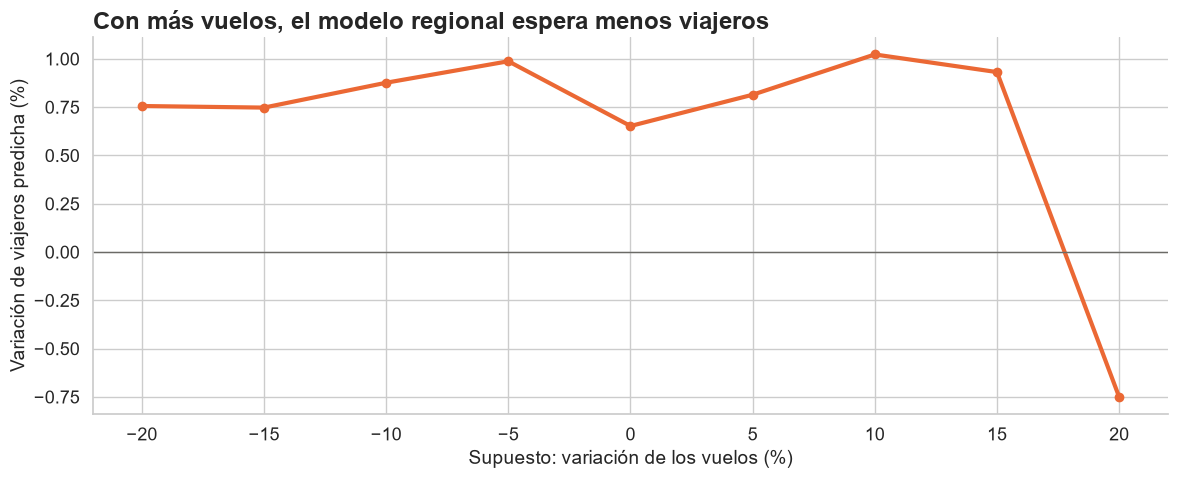

-20    0.8
-15    0.7
-10    0.9
-5     1.0
0      0.7
5      0.8
10     1.0
15     0.9
20    -0.8
dtype: float64

In [21]:
con_vuelos = u_r[u_r.pasajeros_var_l12.notna()]
display(con_vuelos.groupby(con_vuelos.index.year)[["pasajeros_var_l12", "var_viajeros"]].mean().round(1)
        .rename(columns={"pasajeros_var_l12": "Pasajeros de cabotaje hace 12 meses (var. %)",
                         "var_viajeros": "Viajeros (var. %)"}))

rf_reg = cargar("demanda_region_rf.joblib")
fechas_sin_vuelos = pd.date_range("2027-11-01", "2028-10-01", freq="MS")  # sin vuelos observados 12 meses antes
grilla = range(-20, 25, 5)
respuesta = pd.Series({v: np.mean([rf_reg.predict(x_futuro_region(dfr[dfr.region == r], fechas_sin_vuelos,
                                                                  FEATURES_REGION, vuelos_var=v)).mean()
                                   for r in REGIONES]) for v in grilla})
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(respuesta.index, respuesta.values, marker="o", color=NARANJA, lw=3)
ax.axhline(0, color=GRIS, lw=1)
ax.set(title="Con más vuelos, el modelo regional espera menos viajeros", xlabel="Supuesto: variación de los vuelos (%)",
       ylabel="Variación de viajeros predicha (%)")
plt.tight_layout(); plt.show()
respuesta.round(1)

**Qué leemos.** Con el modelo final, el supuesto de vuelos casi no mueve la predicción: entre −20 % y +15 % la variación de viajeros queda entre +0,7 % y +1,0 %, y con +20 % pasa a −0,8 %. Sin la macro, la misma curva iba de +5 % a −5 %: era la caída de 2024 atribuida a los vuelos. Igual, con tan pocos años, los escenarios dejan los vuelos **sin cambio (0 %)** en los meses sin vuelos observados.

### Los escenarios mueven las regiones, en el orden esperado

Como el modelo regional usa la macro, Optimista, Base y Pesimista dan proyecciones distintas por región (la API lo informa con `escenarios_afectan_region: true`, calculado desde las variables del modelo). Verificamos el orden esperado en la ventana (Optimista ≥ Base ≥ Pesimista), mes por mes:

In [22]:
from modelos import ESCENARIOS_REGION
VENT = pd.date_range("2026-11-01", "2027-10-01", freq="MS")
por_esc = {e: pd.concat({r: proyectar_region(rf_reg, dfr, r, VENT[-1], **ESCENARIOS_REGION[e]).loc[VENT] for r in REGIONES})
           for e in ["Pesimista", "Base", "Optimista"]}
esc = pd.DataFrame(por_esc)
orden = esc.groupby(level=0).sum().div(1e6).round(3)
orden["¿Optimista ≥ Base ≥ Pesimista?"] = (orden.Optimista >= orden.Base) & (orden.Base >= orden.Pesimista)
orden["Meses con Optimista < Base"] = (esc.Optimista < esc.Base).groupby(level=0).sum()
orden["Meses con Pesimista > Base"] = (esc.Pesimista > esc.Base).groupby(level=0).sum()
print("Viajeros en la ventana, en millones")
orden

Viajeros en la ventana, en millones


,Pesimista,Base,Optimista,¿Optimista ≥ Base ≥ Pesimista?,Meses con Optimista < Base,Meses con Pesimista > Base
Buenos Aires,1.796,1.899,2.110,True,0,0
CABA,1.930,2.080,2.283,True,0,0
Cuyo,1.178,1.272,1.345,True,0,0
Córdoba,2.290,2.415,2.622,True,0,0
Litoral,2.313,2.423,2.777,True,0,0
Norte,1.825,1.953,2.124,True,0,0
Patagonia,2.734,2.901,3.117,True,0,0


**Qué leemos.** Con las restricciones de monotonía, el orden **se cumple en los 84 meses × región**: ningún mes con el optimista por debajo del base ni con el pesimista por encima. Sin restricciones había 27 meses fuera de orden (Norte en los 12 meses). El tipo de cambio real (+15 % en el pesimista) no está restringido, pero no entró al modelo regional en la selección, así que no puede desordenar los escenarios. En la ventana, la distancia entre pesimista y optimista va de 1,18 M a 1,35 M en Cuyo hasta 2,31 M a 2,78 M en Litoral.

### Horizonte: meses puente, ventana de pronóstico y por qué el error crece

Hoy es **25 de octubre de 2026** y la ventana de pronóstico son los **12 meses siguientes: noviembre 2026 a octubre 2027**. Pero el último dato real de la EOH es **noviembre 2025** (se revisaron el CSV de yvera, la API de datos.gob.ar y la página del INDEC: no hay meses posteriores publicados en formato abierto). Los **11 meses de diciembre 2025 a octubre 2026 ya pasaron pero no tienen dato**: se estiman igual que el pronóstico y la API los marca como **"puente"**. Lo posterior a octubre 2027 se marca como **"tendencia"**.

Como el método arma cada mes con "mismo mes del año anterior × (1 + variación)", un mes de la ventana se apoya en un mes puente que ya es una estimación: **de diciembre 2026 a octubre 2027, cada pronóstico encadena dos variaciones estimadas** (solo noviembre 2026 se apoya en un dato real, noviembre 2025). El error de las dos se acumula. Lo medimos en el modelo nacional: predecir un año a 2 años de distancia (entrenando hasta dos años antes y encadenando dos variaciones), con la macro real de esos años.

In [23]:
filas = []
for anio in ANIOS_BACKTEST:
    if anio - 1 in (2020, 2021, 2022):
        continue
    t1, t0 = d[d.index.year == anio], d[d.index.year == anio - 1]
    hasta_1, hasta_2 = d[d.index.year < anio], d[d.index.year < anio - 1]
    rf_1 = modelos_demanda()["Random Forest"].fit(hasta_1[FEATURES], hasta_1.var_viajeros)
    rf_2 = modelos_demanda()["Random Forest"].fit(hasta_2[FEATURES], hasta_2.var_viajeros)
    var_puente = pd.Series(rf_2.predict(t0[FEATURES]), index=t0.index + pd.DateOffset(years=1)).reindex(t1.index)
    base_2 = df[TARGET].shift(24).reindex(t1.index)
    filas.append({"Año": anio,
                  "RF a 1 año": mape(t1[TARGET], a_viajeros(t1, rf_1.predict(t1[FEATURES]))),
                  "RF a 2 años": mape(t1[TARGET], base_2 * (1 + var_puente / 100) * (1 + rf_2.predict(t1[FEATURES]) / 100)),
                  "Baseline a 1 año": mape(t1[TARGET], t1.viajeros_anio_anterior),
                  "Baseline a 2 años": mape(t1[TARGET], base_2)})
horizonte_err = pd.DataFrame(filas).set_index("Año")
horizonte_err.loc["Promedio"] = horizonte_err.mean()
horizonte_err.round(1)

,RF a 1 año,RF a 2 años,Baseline a 1 año,Baseline a 2 años
Año,,,,
2014,6.0,4.9,4.4,3.3
2015,3.9,8.4,4.5,6.4
2016,5.7,5.7,5.7,6.2
2017,6.0,6.0,7.4,6.4
2018,3.5,7.7,5.2,7.4
2019,2.6,3.3,4.0,3.6
2024,14.4,19.6,14.8,17.7
2025,3.8,15.7,4.8,11.5
Promedio,5.7,8.9,6.4,7.8


**Qué leemos.** A 1 año, el RF nacional se equivoca **5,7 %** en promedio (en estos 8 años); a 2 años, **8,9 %**. La regla simple pasa de 6,4 % a 7,8 %: a 2 años el RF ya **no le gana**, porque los errores de las dos variaciones se suman (2025 es el caso extremo: 3,8 % a 1 año, 15,7 % a 2 años, porque arrastra el error de 2024). Y eso es con la macro **real**; en un pronóstico la macro también es un supuesto. Para la ventana noviembre 2026 – octubre 2027 hay que leer el error histórico (±6 % nacional, ±9 % regional) como **un piso**: el error esperado es mayor, del orden de lo medido a 2 años.

### ¿Por qué casi todo queda por debajo de lo normal? (todas las regiones)

La regla de precios compara la proyección de cada mes con un valor **normal** de ese mes, armado solo con meses **reales** (nunca proyectados) y sin pandemia. La primera versión usaba el **promedio de los últimos 3 años**, y con eso casi todos los meses de la ventana quedaban por debajo de lo normal en Buenos Aires, CABA y Cuyo. Revisamos tres hipótesis:

1. **La referencia está inflada:** el promedio de 3 años (2023–2025) incluye 2023, el último año del PreViaje.
2. **El modelo arrastra la caída de 2024:** predice variaciones negativas para la ventana.
3. **La recursión de los meses puente:** cada mes de la ventana se apoya en un mes puente estimado, y si los puentes bajan, la ventana baja con ellos.

In [24]:
def referencia(real, fecha, tipo):
    previos = real[(real.index.month == fecha.month) & (real.index < fecha)]
    return {"Promedio 3 años": previos.iloc[-3:].mean(), "Mediana 3 años": previos.iloc[-3:].median(),
            "Último año real": previos.iloc[-1]}[tipo]

TIPOS = ["Promedio 3 años", "Mediana 3 años", "Último año real"]
ventana = pd.date_range("2026-11-01", "2027-10-01", freq="MS")
filas = []
for r in REGIONES:
    d_r = dfr[dfr.region == r]
    real = d_r.loc[~d_r.pandemia, TARGET].dropna()
    proy = proyectar_region(rf_reg, dfr, r, ventana[-1])
    serie = pd.concat([real, proy])
    ene_nov = d_r[TARGET][d_r.index.month <= 11]
    anual = ene_nov.groupby(ene_nov.index.year).sum()
    fila = {"Región": r, "2023 vs. 2025, ene–nov (%)": (anual[2023] / anual[2025] - 1) * 100,
            "Variación de los puentes (%)": (proy.loc[:"2026-10"] / serie.shift(12).reindex(proy.loc[:"2026-10"].index) - 1).mean() * 100,
            "Variación en la ventana (%)": (proy.loc[ventana] / serie.shift(12).reindex(ventana) - 1).mean() * 100}
    for t in TIPOS:
        dv = proy.loc[ventana] / [referencia(real, f, t) for f in ventana] - 1
        fila[f"Desvío vs. {t.lower()} (%)"] = dv.mean() * 100
        fila[f"Meses abajo ({t.lower()})"] = int((dv < 0).sum())
    filas.append(fila)
diagnostico = pd.DataFrame(filas).set_index("Región")
diagnostico.round(1).T

Región,Buenos Aires,CABA,Córdoba,Cuyo,Litoral,Norte,Patagonia
"2023 vs. 2025, ene–nov (%)",15.8,15.5,-2.1,24.4,1.9,13.0,11.0
Variación de los puentes (%),-0.2,0.7,1.8,1.3,-0.7,1.4,1.5
Variación en la ventana (%),-0.2,1.3,1.3,1.0,-0.2,1.2,1.2
Desvío vs. promedio 3 años (%),-5.7,-1.9,7.0,-6.5,1.6,-0.6,-0.5
Meses abajo (promedio 3 años),10.0,8.0,1.0,11.0,5.0,7.0,8.0
Desvío vs. mediana 3 años (%),-3.6,0.2,6.1,-3.1,0.1,1.2,1.4
Meses abajo (mediana 3 años),9.0,3.0,1.0,7.0,9.0,2.0,3.0
Desvío vs. último año real (%),-0.4,1.9,3.0,2.2,-0.9,2.5,2.6
Meses abajo (último año real),7.0,1.0,0.0,0.0,10.0,0.0,0.0


In [25]:
# ¿Qué referencia anticipa mejor el mismo mes del año siguiente? Backtest por año, con años reales anteriores
filas = []
for r in REGIONES:
    d_r = dfr[dfr.region == r]
    real = d_r.loc[~d_r.pandemia, TARGET].dropna()
    u_reg = utilizables(d_r)
    for anio in ANIOS_BACKTEST:
        prueba = u_reg[u_reg.index.year == anio]
        for t in TIPOS:
            ref = np.array([referencia(real, f, t) for f in prueba.index])
            filas.append({"Región": r, "Año": anio, "Referencia": t, "MAPE": mape(prueba[TARGET], ref)})
ref_bt = pd.DataFrame(filas)
tabla_ref = ref_bt.pivot_table(index="Referencia", columns="Año", values="MAPE")
tabla_ref["Promedio"] = ref_bt.groupby(["Referencia", "Región"]).MAPE.mean().groupby("Referencia").mean()
tabla_ref.round(1).sort_values("Promedio")

Año,2014,2015,2016,2017,2018,2019,2023,2024,2025,Promedio
Referencia,,,,,,,,,,
Último año real,6.7,7.3,8.8,8.2,7.6,8.5,10.4,16.8,7.9,9.1
Promedio 3 años,9.3,9.0,9.6,9.0,6.4,9.9,7.8,18.1,11.5,10.1
Mediana 3 años,9.7,9.0,9.8,9.1,7.0,10.6,7.8,17.6,12.3,10.3


**A la distancia de la ventana.** Arriba la referencia se compara a 1 año, con el año anterior real. En la ventana, en cambio, el último año real (2025) está **2 años** antes del mes a pronosticar, y el año anterior (2026) es un mes **puente estimado**. Repetimos el *backtest* así: para cada año de prueba, el modelo regional se entrena hasta 2 años antes, estima el año del medio (puente) y se mide cada referencia contra el dato real. Se suma la referencia **`anio_anterior`**: el mismo mes 12 meses antes, real o estimado (con ella, el desvío es la variación interanual que predice el modelo).

In [26]:
filas = []
for anio in ANIOS_BACKTEST:
    if anio - 1 not in set(u_r.index.year):
        continue
    entrenamiento = u_r[u_r.index.year < anio - 1]
    rf_bt = pipeline_region(modelos_region()["Random Forest"], FEATURES_REGION).fit(entrenamiento[FEATURES_REGION], entrenamiento.var_viajeros)
    for r in REGIONES:
        d_r = dfr[dfr.region == r]
        u_reg = u_r[u_r.region == r]
        previo, prueba = u_reg[u_reg.index.year == anio - 1], u_reg[u_reg.index.year == anio]
        puente_bt = pd.Series(a_viajeros(previo, rf_bt.predict(previo[FEATURES_REGION])).values, index=previo.index)
        real = d_r.loc[~d_r.pandemia, TARGET].dropna()
        for f, y in prueba[TARGET].items():
            previos = real[(real.index.month == f.month) & (real.index.year <= anio - 2)]
            refs = {"Año anterior (puente estimado)": puente_bt.get(f - pd.DateOffset(years=1), np.nan),
                    "Último año real": previos.iloc[-1], "Promedio 3 años": previos.iloc[-3:].mean(),
                    "Mediana 3 años": previos.iloc[-3:].median()}
            filas += [{"Región": r, "Año": anio, "Referencia": n, "APE": abs(v / y - 1) * 100} for n, v in refs.items()]
ref_2 = pd.DataFrame(filas).dropna()
por_region_anio = ref_2.groupby(["Referencia", "Región", "Año"]).APE.mean()
tabla_ref_2 = por_region_anio.groupby(["Referencia", "Año"]).mean().unstack()
tabla_ref_2["Promedio"] = por_region_anio.groupby(["Referencia", "Región"]).mean().groupby("Referencia").mean()
tabla_ref_2.round(1).sort_values("Promedio")

Año,2014,2015,2016,2017,2018,2019,2024,2025,Promedio
Referencia,,,,,,,,,
Año anterior (puente estimado),12.1,11.3,10.5,9.6,10.1,11.4,21.2,13.3,12.4
Promedio 3 años,11.5,11.4,13.5,11.3,7.4,10.8,18.2,15.4,12.4
Último año real,11.9,10.1,11.0,9.0,9.6,11.8,21.5,14.2,12.4
Mediana 3 años,12.2,11.7,12.4,11.6,7.7,11.1,17.6,15.2,12.5


**Qué leemos.**

1. **Sí, el promedio de 3 años estaba inflado.** Comparando enero a noviembre, 2023 superó a 2025 en **+24 % en Cuyo, +16 % en Buenos Aires y CABA, +13 % en el Norte y +11 % en Patagonia** (en Litoral +2 % y en Córdoba −2 %). Con el promedio de 3 años, Cuyo queda debajo de lo normal en 11 de los 12 meses de la ventana y Buenos Aires en 10.
2. **El modelo no arrastra la caída de 2024:** en la ventana predice variaciones de −0,2 % a +1,3 % según la región.
3. **La recursión pesa poco:** los meses puente varían entre −0,7 % (Litoral) y +1,8 % (Córdoba).

**Qué referencia usar.**

- **A 1 año**, el **mismo mes del último año real** anticipa mejor que el promedio o la mediana de 3 años (9,1 % contra 10,1 % y 10,3 %). A 1 año, `anio_anterior` es exactamente lo mismo (el año anterior es real).
- **A 2 años** (la situación de la ventana) quedan prácticamente empatadas: último año real **12,38 %**, promedio de 3 años 12,44 %, **`anio_anterior` 12,45 %** y mediana 12,45 %. `anio_anterior` no mejora (compararse con un mes puente suma el error del modelo).
- **Se mantiene `ultimo_anio` por defecto** (`precios.REFERENCIA`); `anio_anterior`, el promedio y la mediana quedan como opción en `POST /precios`. El desvío de un mes de 2027 acumula dos años de variación contra 2025, y hay que decirlo en el front. Con el modelo final (escenario base), en las cadenas de ejemplo las 252 publicaciones × mes de la ventana quedan en **152 sube, 0 baja y 100 se mantiene**; con `anio_anterior` serían 29, 0 y 223. En el pesimista: 0, 223 y 29; en el optimista: 252, 0 y 0.

### Decisiones tomadas (demanda por región y precios)

**1. El Random Forest regional usa salario real, inflación y actividad con restricciones de monotonía.** En el *backtest* se equivoca **9,01 %** contra **9,12 %** de repetir el mismo mes del año anterior: le gana por poco en promedio, gana claro en CABA y Litoral, empata en Buenos Aires y Córdoba y pierde en Cuyo, Norte y Patagonia. Se mantiene porque:

- **aporta la estructura**: un solo modelo para las 7 regiones con la región y el mes (estacionalidad propia de cada región), que es lo que necesita una empresa para mirar su destino;
- **incorpora la conectividad aérea** (vuelos de cabotaje con 12 meses de rezago) y la **macro con el signo esperado**, así que **responde a los escenarios en el orden correcto** en todas las regiones;
- **deja lista la base** para sumar datos por región cuando existan (tarifas, ocupación por localidad, vuelos por aeropuerto de destino) y medirlos con el mismo *backtest*.

Hay que comunicarlo así: **la mejora sobre la regla simple es chica** (0,1 puntos) y el error esperado en la ventana es mayor que el histórico (meses puente).

**2. La referencia de la regla de precios es el mismo mes del último año real** (`ultimo_anio`): a 1 año anticipa mejor que el promedio de 3 años (9,1 % contra 10,1 %) y no arrastra el nivel de 2023; a 2 años empata con las demás y `anio_anterior` no la mejora (12,45 % contra 12,38 %).

In [27]:
decision_rf = pd.DataFrame({
    "Baseline (mismo mes año anterior)": mape_reg[("Final (con selección de variables)", BASE_R)],
    "Random Forest regional": mape_reg[("Final (con selección de variables)", "Random Forest")],
})
decision_rf["Diferencia (p.p.)"] = decision_rf["Random Forest regional"] - decision_rf["Baseline (mismo mes año anterior)"]
decision_rf["Resultado"] = np.select([decision_rf["Diferencia (p.p.)"] < -0.1, decision_rf["Diferencia (p.p.)"] > 0.1],
                                     ["gana", "pierde"], "empata")
decision_rf.round(2)

,Baseline (mismo mes año anterior),Random Forest regional,Diferencia (p.p.),Resultado
region,,,,
Buenos Aires,10.58,10.54,-0.03,empata
CABA,8.64,7.40,-1.24,gana
Cuyo,9.86,10.89,1.03,pierde
Córdoba,8.42,8.42,0.00,empata
Litoral,9.07,7.65,-1.42,gana
Norte,8.56,9.11,0.55,pierde
Patagonia,8.71,9.05,0.33,pierde
Promedio,9.12,9.01,-0.11,gana


---

## Clasificador: ¿qué turista se aloja en hotel?

**Datos:** microdatos de la EVyTH (2012 a 2024-T2), un registro por persona y viaje, **ponderado por el factor de expansión** (`pondera`) para que represente a la población. **Partición temporal:** se entrena hasta 2021 y se prueba en 2022–2024 (viajes posteriores, como en la vida real). Ambos modelos usan `class_weight="balanced"` porque solo ~1 de cada 4 viajes va a hotel.

In [28]:
ev = cargar_evyth()
X_tr, y_tr, w_tr, X_te, y_te, w_te = datos_hotel(ev)
arbol_h, rf_h = cargar("hotel_arbol.joblib"), cargar("hotel_rf.joblib")
p_arbol, p_rf = arbol_h.predict_proba(X_te)[:, 1], rf_h.predict_proba(X_te)[:, 1]
tasa = np.average(y_te, weights=w_te)
print(f"Viajes de entrenamiento: {miles(len(X_tr))} · de prueba: {miles(len(X_te))}")
print(f"En 2022–2024, {pct(tasa * 100, 0)} de los viajes se alojó en hotel.")
print(f"Piso (decir siempre 'no hotel'): exactitud {pct((1 - tasa) * 100, 0)} pero no encuentra a ningún huésped; AUC 0,50")
pd.DataFrame({"AUC en prueba": [roc_auc_score(y_te, p, sample_weight=w_te) for p in (p_arbol, p_rf)]},
             index=["Árbol de decisión", "Random Forest"]).round(3)

Viajes de entrenamiento: 198.620 · de prueba: 43.447
En 2022–2024, 24 % de los viajes se alojó en hotel.
Piso (decir siempre 'no hotel'): exactitud 76 % pero no encuentra a ningún huésped; AUC 0,50


,AUC en prueba
Árbol de decisión,0.747
Random Forest,0.779


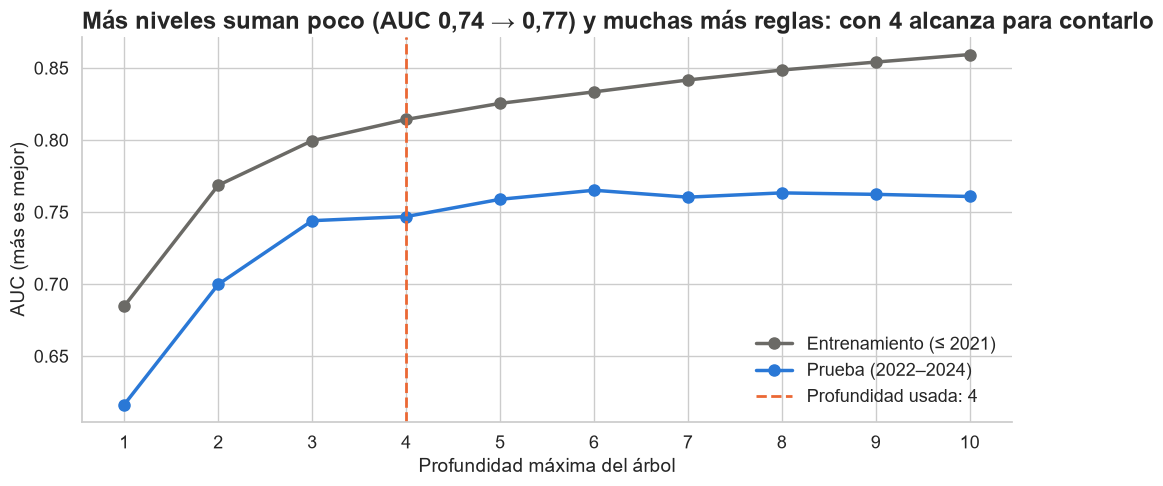

profundidad,1,2,3,4,5,6,7,8,9,10
Entrenamiento,0.685,0.769,0.800,0.814,0.825,0.833,0.842,0.849,0.854,0.859
Prueba,0.616,0.700,0.744,0.747,0.759,0.765,0.760,0.763,0.762,0.761


In [29]:
# Profundidad del árbol de hotel: misma lógica de la curva train vs. prueba
filas = []
for p in range(1, 11):
    m = DecisionTreeClassifier(max_depth=p, min_samples_leaf=200, class_weight="balanced", random_state=SEMILLA)
    m.fit(X_tr, y_tr, sample_weight=w_tr)
    filas.append({"profundidad": p,
                  "Entrenamiento": roc_auc_score(y_tr, m.predict_proba(X_tr)[:, 1], sample_weight=w_tr),
                  "Prueba": roc_auc_score(y_te, m.predict_proba(X_te)[:, 1], sample_weight=w_te)})
curva_h = pd.DataFrame(filas).set_index("profundidad")
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(curva_h.index, curva_h["Entrenamiento"], color=GRIS, lw=2.5, marker="o", ms=8, label="Entrenamiento (≤ 2021)")
ax.plot(curva_h.index, curva_h["Prueba"], color=AZUL, lw=2.5, marker="o", ms=8, label="Prueba (2022–2024)")
ax.axvline(arbol_h.get_depth(), color=NARANJA, ls="--", lw=2, label=f"Profundidad usada: {arbol_h.get_depth()}")
ax.set_xlabel("Profundidad máxima del árbol"); ax.set_ylabel("AUC (más es mejor)")
ax.set_xticks(curva_h.index); ax.legend(frameon=False, loc="lower right")
ax.set_title("Más niveles suman poco (AUC 0,74 → 0,77) y muchas más reglas: con 4 alcanza para contarlo")
plt.show()
curva_h.round(3).T

### Matriz de confusión: los dos errores no cuestan lo mismo

Usamos el clasificador para **decidir a quién dirigir una promoción de hotel**:

- **Falso positivo** (el modelo dice “hotel” y la persona no iba a ir): se le manda una promoción que no usa. **Costo bajo**: el costo del contacto o del anuncio.
- **Falso negativo** (el modelo dice “no hotel” y la persona sí iba): **perdemos a un huésped** que podría haber elegido nuestra cadena. **Costo alto**: una estadía entera de ingresos.

Por eso conviene un modelo que **encuentre a la mayoría de los huéspedes** (*recall* alto), aunque algunas promociones se “desperdicien” (*precisión* más baja).

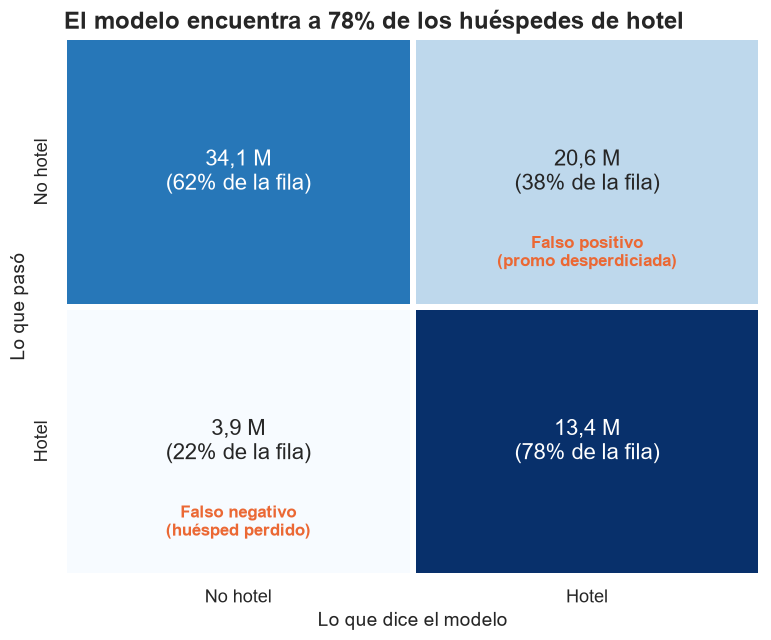

Viajes expandidos a la población (millones de viajes-persona, 2022–2024). Random Forest, umbral 0,5.


In [30]:
UMBRAL = 0.5
pred = (p_rf >= UMBRAL).astype(int)
cm = confusion_matrix(y_te, pred, sample_weight=w_te)
etiquetas = ["No hotel", "Hotel"]
texto = np.array([[f"{millones(cm[i, j], 1)}\n({cm[i, j] / cm[i].sum():.0%} de la fila)" for j in range(2)] for i in range(2)])
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=texto, fmt="", cmap="Blues", cbar=False, linewidths=3,
            linecolor="white", annot_kws={"size": 16}, xticklabels=etiquetas, yticklabels=etiquetas, ax=ax)
ax.set_xlabel("Lo que dice el modelo"); ax.set_ylabel("Lo que pasó")
ax.set_title(f"El modelo encuentra a {cm[1, 1] / cm[1].sum():.0%} de los huéspedes de hotel")
for (i, j), nombre in {(0, 1): "Falso positivo\n(promo desperdiciada)", (1, 0): "Falso negativo\n(huésped perdido)"}.items():
    ax.text(j + 0.5, i + 0.85, nombre, ha="center", fontsize=12, color=NARANJA, fontweight="bold")
plt.show()
print("Viajes expandidos a la población (millones de viajes-persona, 2022–2024). Random Forest, umbral 0,5.")

In [31]:
filas = []
for u in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pr = (p_rf >= u).astype(int)
    filas.append({"Umbral": u,
                  "Huéspedes encontrados (recall)": recall_score(y_te, pr, sample_weight=w_te),
                  "De cada 100 promos, cuántas llegan a un huésped (precisión)": precision_score(y_te, pr, sample_weight=w_te) * 100,
                  "% de viajeros a contactar": np.average(pr, weights=w_te) * 100})
umbrales = pd.DataFrame(filas).set_index("Umbral")
umbrales["Huéspedes encontrados (recall)"] *= 100
umbrales.round(0)

,Huéspedes encontrados (recall),"De cada 100 promos, cuántas llegan a un huésped (precisión)",% de viajeros a contactar
Umbral,,,
0.3,91.0,32.0,69.0
0.4,86.0,34.0,60.0
0.5,78.0,39.0,47.0
0.6,65.0,47.0,33.0
0.7,47.0,56.0,20.0


**Qué leemos.** Con el umbral 0,5 el modelo encuentra a **casi 8 de cada 10 huéspedes** contactando a menos de la mitad de los viajeros; 4 de cada 10 promociones llegan a alguien que efectivamente se aloja en hotel (contra 2,4 de cada 10 si se mandaran al azar). Si la promoción es barata (mail, redes), conviene **bajar el umbral** y llegar a más huéspedes; si es cara (descuento fuerte), **subirlo**.

### Reglas del árbol: los segmentos, en castellano

In [32]:
from regiones import CODIGO_REGION
REGION = {codigo: region for region, codigo in CODIGO_REGION.items()}  # las 7 regiones de la EOH
MOTIVO = {1: "ocio", 2: "visita a familiares/amigos", 3: "trabajo", 4: "estudios", 5: "salud", 6: "religioso",
          7: "compras", 8: "otros", 99: "sin dato"}
TRANSPORTE = {1: "auto propio", 2: "ómnibus", 3: "tren", 4: "avión", 5: "embarcación", 6: "taxi/remís", 8: "otro",
              99: "sin dato"}
GRUPO = {1: "1-2 personas", 2: "3-4 personas", 3: "5 o más personas"}
CATEGORICAS = {"region_destino": ("destino", REGION), "region_origen": ("origen", REGION), "motivo": ("motivo", MOTIVO),
               "transporte": ("transporte", TRANSPORTE), "tamanio_grupo": ("grupo", GRUPO),
               "quintil": ("quintil de ingreso", {i: str(i) for i in range(1, 6)}),
               "trimestre": ("trimestre", {i: str(i) for i in range(1, 5)})}

def condicion_hotel(f, lo, hi):
    if f in CATEGORICAS:
        nombre, mapa = CATEGORICAS[f]
        valores = [v for k, v in mapa.items() if lo < k <= hi]
        if len(valores) == len(mapa) - 1 and f in ("motivo", "transporte"):
            excluido = [v for k, v in mapa.items() if not (lo < k <= hi)][0]
            return f"{nombre}: cualquiera menos {excluido}"
        return f"{nombre}: " + (", ".join(valores[:-1]) + " o " + valores[-1] if len(valores) > 1 else valores[0])
    if f == "noches":
        if np.isinf(lo): return f"≤ {int(hi)} noches"
        if np.isinf(hi): return f"≥ {int(lo) + 1} noches"
        return f"entre {int(lo) + 1} y {int(hi)} noches"
    return f"{f} en ({lo}, {hi}]"

hoja_te = arbol_h.apply(X_te)
stats = pd.DataFrame({"hoja": hoja_te, "w": w_te.values, "hotel": y_te.values})
stats = stats.groupby("hoja").apply(lambda g: pd.Series({"% de los viajes": g.w.sum() / w_te.sum() * 100,
                                                         "% en hotel (2022–2024)": np.average(g.hotel, weights=g.w) * 100}))
filas = [{"hoja": n, "Regla": "Si " + " · ".join(condicion_hotel(f, *v) for f, v in cond.items())}
         for n, cond in hojas(arbol_h, FEATURES_HOTEL)]
reglas_hotel = pd.DataFrame(filas).set_index("hoja").join(stats).sort_values("% en hotel (2022–2024)", ascending=False)
hot = reglas_hotel["% en hotel (2022–2024)"]
reglas_hotel["Veces el promedio"] = (hot / (tasa * 100)).round(1)
reglas_hotel["Decisión"] = np.select([hot >= 2 * tasa * 100, hot >= tasa * 100], ["Prioridad alta", "Prioridad media"], "No apuntar")
with pd.option_context("display.max_colwidth", None):
    display(reglas_hotel.round(1).style.hide(axis="index").format(precision=1)
            .set_properties(**{"text-align": "left", "font-size": "13px"}))

Regla,% de los viajes,% en hotel (2022–2024),Veces el promedio,Decisión
"Si motivo: ocio · destino: CABA, Córdoba, Cuyo, Litoral, Norte o Patagonia · transporte: cualquiera menos auto propio · quintil de ingreso: 4 o 5",6.5,65.6,2.7,Prioridad alta
"Si motivo: ocio · destino: CABA, Córdoba, Cuyo, Litoral, Norte o Patagonia · transporte: cualquiera menos auto propio · quintil de ingreso: 1, 2 o 3",3.8,52.8,2.2,Prioridad alta
"Si motivo: trabajo, estudios, salud, religioso o compras · grupo: 1-2 personas o 3-4 personas",2.9,43.1,1.8,Prioridad media
"Si motivo: ocio · destino: Buenos Aires · transporte: embarcación, taxi/remís, otro o sin dato",0.2,39.7,1.7,Prioridad media
"Si motivo: ocio · destino: Buenos Aires · transporte: ómnibus, tren o avión",4.7,38.1,1.6,Prioridad media
"Si motivo: ocio · destino: CABA, Córdoba, Cuyo, Litoral, Norte o Patagonia · transporte: auto propio · ≥ 3 noches",18.1,33.3,1.4,Prioridad media
"Si motivo: ocio · destino: CABA, Córdoba, Cuyo, Litoral, Norte o Patagonia · transporte: auto propio · ≤ 2 noches",10.2,26.2,1.1,Prioridad media
"Si motivo: otros o sin dato · origen: Córdoba, Cuyo, Litoral, Norte o Patagonia",0.9,19.3,0.8,No apuntar
"Si motivo: trabajo, estudios, salud, religioso o compras · grupo: 5 o más personas",0.3,17.7,0.7,No apuntar
Si motivo: ocio · destino: Buenos Aires · transporte: auto propio · ≤ 10 noches,22.4,17.1,0.7,No apuntar


**Las reglas que importan para la Gerencia Comercial:**

Porcentajes medidos en 2022–2024 (datos de prueba); el promedio general es 24 %.

1. **Si el viaje es de ocio, fuera de la provincia de Buenos Aires (CABA, Córdoba, Cuyo, Litoral, Norte o Patagonia), sin auto propio (ómnibus, avión…) y de un hogar de quintil 4 o 5 → 2 de cada 3 van a hotel** (66 %, casi el triple del promedio). Es el **segmento núcleo**: turismo de ocio de ingresos medios-altos que llega en transporte público o avión.
2. **El mismo viaje en hogares de quintiles 1 a 3 → 1 de cada 2 va a hotel** (53 %). Sin auto, en el interior, el hotel es la opción natural aunque el ingreso sea menor: público para tarifas promocionales.
3. **Si el viaje es por trabajo, estudios, salud o similares y viajan hasta 4 personas → 43 % en hotel.** Segmento corporativo, menos estacional: sirve para llenar la temporada baja.
4. **Si es de ocio y en auto propio → entre 8 % y 33 % en hotel** según destino y noches: compite con la vivienda alquilada por temporada y la segunda vivienda. Es el segmento más grande (más de la mitad de los viajes): ahí se gana **convirtiendo** con precio o paquetes.
5. **Si el motivo es visitar a familiares o amigos → casi nunca hotel** (entre 2 % y 6 % en la mayoría de los casos). No es el público de una promo de hotel.

### Importancia por permutación (Random Forest de hotel)

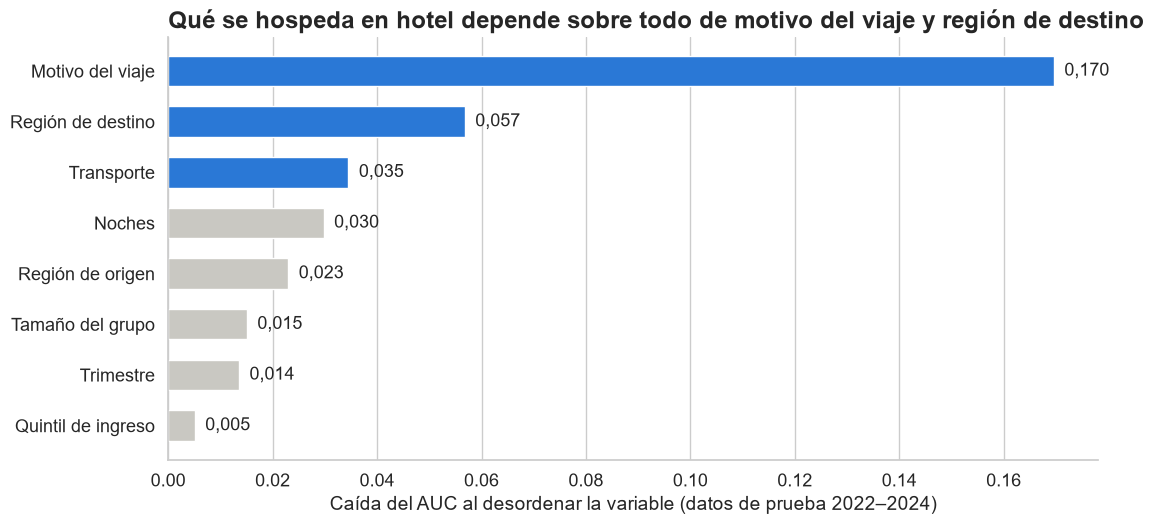

In [33]:
NOMBRES_HOTEL = {"quintil": "Quintil de ingreso", "region_origen": "Región de origen", "region_destino": "Región de destino",
                 "trimestre": "Trimestre", "noches": "Noches", "tamanio_grupo": "Tamaño del grupo", "motivo": "Motivo del viaje",
                 "transporte": "Transporte"}
muestra = X_te.sample(10000, random_state=SEMILLA).index
r = permutation_importance(rf_h, X_te.loc[muestra], y_te.loc[muestra], sample_weight=w_te.loc[muestra], scoring="roc_auc",
                           n_repeats=5, random_state=SEMILLA, n_jobs=-1)
imp_h = pd.Series(r.importances_mean, index=FEATURES_HOTEL).sort_values()
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.barh([NOMBRES_HOTEL[f] for f in imp_h.index], imp_h.values, height=0.6,
        color=[AZUL if v >= imp_h.nlargest(3).min() else GRIS_CLARO for v in imp_h])
for i, v in enumerate(imp_h.values):
    ax.text(v + 0.002, i, f"{v:.3f}".replace(".", ","), va="center", fontsize=13)
ax.set_xlabel("Caída del AUC al desordenar la variable (datos de prueba 2022–2024)")
ax.grid(axis="y", visible=False)
ax.set_title(f"Qué se hospeda en hotel depende sobre todo de {NOMBRES_HOTEL[imp_h.index[-1]].lower()} y {NOMBRES_HOTEL[imp_h.index[-2]].lower()}")
plt.show()

**Lectura de negocio.** El **para qué** viaja la gente (motivo) pesa muchísimo más que cualquier otra cosa: quien visita familia no va a hotel aunque tenga ingresos altos. Después vienen **adónde** va y **en qué** viaja. El quintil de ingreso casi no suma una vez que se conocen motivo, destino y transporte, porque esas variables ya lo reflejan (quien vuela al Norte de vacaciones suele ser de ingresos altos). Como antes: **no es causal** — no dice que subirle el ingreso a alguien lo mande a un hotel, sino qué datos ayudan a reconocer a un huésped probable.

### Segmentos: % de viajes que se alojan en hotel, por quintil de ingreso y región de destino

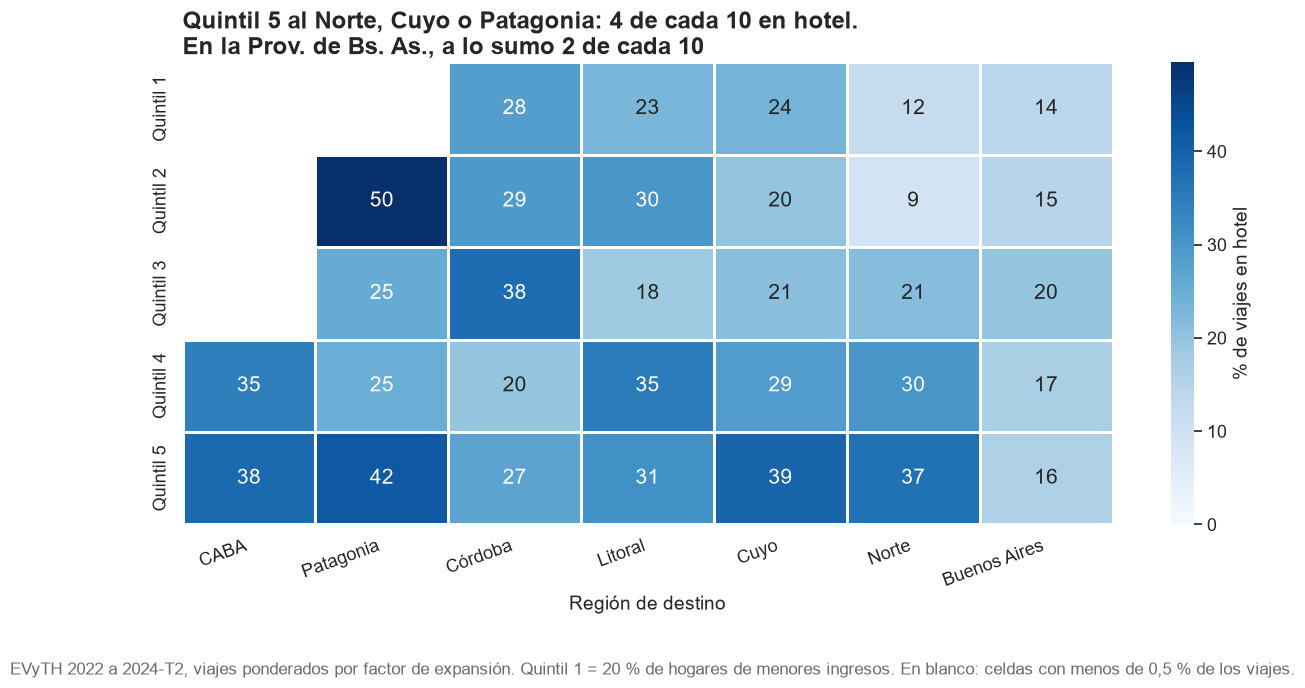

Peso de cada segmento en el total de viajes (%), para dimensionar la promoción:


Destino,CABA,Patagonia,Córdoba,Litoral,Cuyo,Norte,Buenos Aires
Quintil 1,0.2,0.4,0.7,0.9,0.8,1.1,2.6
Quintil 2,0.2,0.8,1.1,1.5,0.9,2.4,3.7
Quintil 3,0.4,0.9,2.3,2.9,1.5,1.9,6.5
Quintil 4,0.6,1.9,3.7,3.9,1.7,2.0,10.1
Quintil 5,1.5,4.4,5.3,6.6,2.9,3.1,18.6


In [34]:
reciente = ev[ev.anio >= 2022].copy()
reciente["Destino"] = reciente.region_destino.map(REGION)
seg = (reciente.groupby(["quintil", "Destino"])
       .apply(lambda g: np.average(g.hotel, weights=g.pondera) * 100).unstack())
orden_dest = seg.mean().sort_values(ascending=False).index
seg = seg[orden_dest]
seg.index = [f"Quintil {q}" for q in seg.index]
volumen = (reciente.groupby(["quintil", "Destino"]).pondera.sum().unstack()[orden_dest] / reciente.pondera.sum() * 100)
volumen.index = seg.index
seg = seg.where(volumen >= 0.5).dropna(axis=1, how="all")  # celdas con muy pocos viajes: no se muestran

fig, ax = plt.subplots(figsize=(15, 6))
sns.heatmap(seg, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=np.nanmax(seg.values), linewidths=2, linecolor="white",
            cbar_kws={"label": "% de viajes en hotel"}, annot_kws={"size": 15}, ax=ax)
ax.set_xlabel("Región de destino"); ax.set_ylabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right")
ax.grid(False)
ax.set_title("Quintil 5 al Norte, Cuyo o Patagonia: 4 de cada 10 en hotel.\nEn la Prov. de Bs. As., a lo sumo 2 de cada 10")
fig.text(0.01, -0.14, "EVyTH 2022 a 2024-T2, viajes ponderados por factor de expansión. Quintil 1 = 20 % de hogares de menores ingresos. En blanco: celdas con menos de 0,5 % de los viajes.",
         fontsize=12, color=GRIS)
fig.savefig(IMG / "segmentos_hotel.png")
plt.show()

print("Peso de cada segmento en el total de viajes (%), para dimensionar la promoción:")
volumen.round(1)

### Decisión: en el Perfil del turista se muestra el dato real, no el puntaje

**3. El medidor del Perfil se muestra como "media"**: el número principal es el **% real de viajes parecidos que fueron a hotel** (mismo quintil, destino y motivo, ponderado por `pondera`), comparado con el **promedio de 24 %** de 2022–2024. El puntaje del Random Forest **no es una probabilidad**: se entrenó con `class_weight="balanced"`, así que 50 significa "turista promedio" y no "1 de cada 2". Por eso un perfil puede tener puntaje 90 y, en la realidad, ir a hotel menos de la mitad de las veces. El puntaje sirve para **ordenar** perfiles; el dato real, para **decir cuántos**.

In [35]:
ejemplos = {
    "Q4 · CABA → Patagonia · ocio · avión": dict(quintil=4, region_origen=CODIGO_REGION["CABA"], region_destino=CODIGO_REGION["Patagonia"],
                                               trimestre=1, noches=7, tamanio_grupo=1, motivo=1, transporte=4),
    "Q4 · Buenos Aires → Córdoba · ocio · ómnibus": dict(quintil=4, region_origen=CODIGO_REGION["Buenos Aires"],
                                                       region_destino=CODIGO_REGION["Córdoba"], trimestre=1, noches=5,
                                                       tamanio_grupo=1, motivo=1, transporte=2),
    "Q3 · CABA → Buenos Aires · ocio · auto": dict(quintil=3, region_origen=CODIGO_REGION["CABA"], region_destino=CODIGO_REGION["Buenos Aires"],
                                                 trimestre=1, noches=5, tamanio_grupo=1, motivo=1, transporte=1),
}
filas = []
for nombre, p in ejemplos.items():
    parecidos = ev[(ev.quintil == p["quintil"]) & (ev.region_destino == p["region_destino"]) & (ev.motivo == p["motivo"])]
    filas.append({"Perfil": nombre,
                  "Puntaje RF (50 = promedio)": rf_h.predict_proba(pd.DataFrame([p])[FEATURES_HOTEL])[0, 1] * 100,
                  "Viajes parecidos en hotel (dato real, %)": np.average(parecidos.hotel, weights=parecidos.pondera) * 100,
                  "Promedio 2022–2024 (%)": tasa * 100})
pd.DataFrame(filas).set_index("Perfil").round(0)

,Puntaje RF (50 = promedio),"Viajes parecidos en hotel (dato real, %)",Promedio 2022–2024 (%)
Perfil,,,
Q4 · CABA → Patagonia · ocio · avión,90.0,46.0,24.0
Q4 · Buenos Aires → Córdoba · ocio · ómnibus,91.0,38.0,24.0
Q3 · CABA → Buenos Aires · ocio · auto,56.0,23.0,24.0


**Qué leemos.** En el **Norte y Cuyo el uso de hotel crece con el ingreso** (en el Norte pasa de 12 % en el quintil 1 a 37 % en el quintil 5; en Cuyo, de 24 % a 39 %). La **Patagonia** es “hotelera” en casi todos los quintiles (destino lejano, sin casa de familia ni segunda vivienda a mano). En la **provincia de Buenos Aires** el hotel no pasa de 2 de cada 10 en ningún quintil: dominan la vivienda alquilada por temporada y la segunda vivienda. La tabla de volumen recuerda que el segmento más “hotelero” no siempre es el más grande: la provincia de Buenos Aires aporta muchos viajes aunque pocos vayan a hotel, así que ahí la estrategia es **convertir** (precio, paquetes) más que **retener**.

---

## Cierre del notebook

| Fase CRISP-DM | Qué hicimos | Resultado |
|---|---|---|
| 3 · Preparación | *Target* = variación interanual; features = cambios macro de 12 meses; pandemia excluida | 181 meses utilizables, 6 predictores |
| 4 · Modelado | Línea base, lineal, árbol (profundidad por curva), Random Forest (OOB), Gradient Boosting (*early stopping*); árbol + RF para hotel | 5 modelos de demanda, 2 de hotel |
| 5 · Evaluación | *Backtest walk-forward* en 9 años; matriz de confusión con costo FP/FN; importancia por permutación | RF 6,0 % vs. 6,3 % de la regla simple; hotel AUC 0,78, encuentra 77 % de los huéspedes |
| Por región | Modelo de Tina corregido: variación interanual, backtest por año, vuelos con rezago, selección de variables | RF monótono con salario, inflación y EMAE: 9,01 % vs. 9,12 % del baseline regional (sin macro: 9,56 %); escenarios ordenados en todas las regiones |
| Horizonte | Último dato real 2025-11; 11 meses puente; ventana 2026-11 → 2027-10 | Error nacional a 2 años: 8,9 % (vs. 5,7 % a 1 año) |

**Qué se nos escapa** (y motiva el notebook 03): el modelo dice cuánto se equivocó en el pasado, pero la gerencia necesita **el número del próximo verano** y **qué pasa si la economía empeora**. Eso es la proyección con escenarios.